# Chapter 03A - Teach word rows by making them useful

### Continuity checkpoint - the whole carry-in is here

**We supplied six questions. How can ordinary text supply thousands?**
That is the new problem, not a new definition of embedding.

| Named example | What you need from it, without reopening another notebook |
|---|---|
| **Lookup microscope:** `the ___ sat` | Local rows: `the=0 -> [2, 0]`, `cat=1 -> [1, 3]`, `sat=2 -> [0, 4]`. Fetch two rows; no guess or learning yet. Here we add averaging. |
| **Learning game:** `cat/dog -> sat/slept`, `bird -> flew/sang` | Six supplied cards trained a fresh four-number table and a separate predictor. Same IDs fetched updated rows. Here text will supply the cards. |

```text
text -> pieces -> IDs -> fetched rows -> context processing -> scores -> checked answer
```

**Fresh-start contract:** each model starts with new random weights. No earlier
table, optimizer state, or local ID numbers transfer. The earlier GPT-2 example
borrowed its tokenizer, not its embedding weights. A seed repeats the initial
draw; it supplies no knowledge.

## What makes the rows worth learning?

Compact rows already give words usable feature inputs. Learning can also give
words used alike features that help the predictor reuse a pattern. In our
controlled game, `cat` and `dog` supported the same answers while keeping
separate IDs and rows.

![Cat and dog share the practice answers sat and slept, while bird has flew and sang. Their IDs and rows stay separate.](images/03a-01-shared-word-features.png)
*Same kinds of questions, useful clues in common. This is the idea we're aiming for, not a plot of trained rows.*

Shared features need not mean identical rows or closeness in every direction.
Shared usage is not synonymy either: `happy` and `sad` can fit the same sentence
slot. Frozen random rows can also support a trained predictor; we train both
parts here, without claiming that this beats a frozen-row baseline.

A guess is still a **shortlist**, not one inevitable answer. For
**the sleepy cat sat on the ___**, `mat`, `rug`, and `floor` could all make
sense. We will inspect probabilities and held-out evidence, not just one winner.

## CBOW preview: let the text supply the answer

Keep **the sleepy cat sat on the mat** as the inspection sentence. Take its
first five-word window and cover the middle:

```text
Window:  the sleepy cat sat on
Clues:   the sleepy ___ sat on
Answer:  cat
```

The four visible words become the input; the covered word is already the answer.
Slide within the sentence and repeat. Ordinary text supplies practice without
anyone writing extra labels. The sentence is a close-up, not the whole training diet.

![Cover cat in the five-word phrase, use the four visible words as context, and keep cat separately as the answer for checking.](images/03a-02-text-makes-practice.png)
*The question mark just marks the gap on the page. CBOW gets the four visible word IDs, not a special mask token.*

### CBOW preview: one wrong guess, two sets of weights

Fetch the four rows, combine them, and score possible answers. Compare the scores
with `cat`. Backpropagation calculates feedback; the optimizer changes the
fetched rows and prediction layers. The embedding row is an input to the
predictor, but a trainable weight of the whole model.

![Rows feed the predictor to make a guess. Comparing the guess with cat gives feedback for the fetched rows and the predictor weights; token IDs stay fixed.](images/03a-03-feedback-teaches-rows.png)
*Two parts learn from the same mistake. The word IDs don't change, and the answer is for checking, not an extra input.*

The same ID subsequently fetches the updated row, not a fresh random draw.
Section 8 isolates this one question on a copy of the model. Input and output
weights remain separate; explicitly sharing them is called *weight tying*,
which we are not doing here.

## Same practice routine, different questions

The next table contrasts CBOW's missing-word question, Skip-gram's neighbour
question, and the reader/writer's ordered answer. CBOW and Skip-gram teach
static word rows; they do not keep writing a passage. The reader/writer is a
preview, with correct earlier answers supplied during practice. Later chapters
slow down its reading and writing.

**Want just the code?** Open the [Python companion](03A-training-skeleton-and-word-objectives.py).
The notebook shows the training base inline; the script imports the same class
from [language_model.py](language_model.py). Each model owns its guessing job;
the practice loop stays shared. The [chapter overview](README.md) holds the onward route.


### Three prediction jobs, three different answers

The same vocabulary can support different questions. `B` is the number of examples in a batch, `V` is the number of possible vocabulary items, `S` is source length, and `T` is target length.

| Objective | What the model sees | What it predicts | Word-score shape |
|---|---|---|---|
| CBOW | Four context IDs with the center removed: `[B, 4]` | One center token per row: `[B]` | `[B, V]` — one set of word scores per example |
| Skip-gram | A center ID repeated once for each neighbor: `[B × 4]` | One neighbor per center-neighbor pair: `[B × 4]` | `[B × 4, V]` — one set of word scores per pair |
| Encoder-decoder | Source IDs `[B, S]` and earlier target IDs `[B, T-1]` | The next target token at every decoder position | `[B, T-1, V]` — one set of word scores at each step |

CBOW and Skip-gram answer one question at a time. The encoder-decoder needs room for several answer positions, so its scores gain a time axis. Keep this table as a shape reference; it isn't a ranking of the models.

### What this small run can and cannot show

For CBOW and Skip-gram, each guess scores **every word in our vocabulary**.
We compare those scores with the correct word. We aren't using the cheaper
shortcut called *negative sampling*, which checks a few chosen wrong words
instead of scoring them all.

For the reader/writer, we've already decided which phrase is the input and
which words complete it. All examples have the same length. During practice,
the writer always gets the **correct previous answer**, not its own guess.
It cannot look back at individual source positions, and we don't need blank
padding slots.

These short runs let us check that learning happens and that each prediction
is matched with the right answer. They do **not** show that we've built a useful
word-meaning model, a translator, or a writer that can keep going well on its own.


## 1 - Shared setup: real stories and one familiar probe sentence

Five hand-written pet phrases would make memorization easy to mistake for learning.
Instead, read the **first 1,000 stories** in the pinned Hugging Face
[TinyStories](https://huggingface.co/datasets/roneneldan/TinyStories) file.
These are real dataset examples (synthetic children's stories), not sentences assembled to
make our word map look good.

Split each story at sentence boundaries, keeping sentences with at least five words.
Then append exactly **one independent document**, **the sleepy cat sat on the mat**, at the
**end**. It is not repeated, weighted, or joined to the preceding story. Its three windows
let you watch familiar questions before and after ordinary real-text training.

The shared tokenizer lowercases words and retains internal apostrophes. Seeds and one CPU
thread make the run repeatable on this setup; different libraries can still change results.
We use 32-number rows, batches of at most 512, and bounded **10 / 4 / 6 epochs** for
CBOW / Skip-gram / the writer. Each fit prints elapsed time. Section 13 adds a separate,
larger held-out comparison; the whole cached default lesson is intended for a few CPU minutes.

**Predict:** After one appearance among thousands of sentences, must `mat` become the
writer's first guess? Keep probability, rank, and the actual shortlist to find out.


In [1]:
# ── 1 - Read real stories; append one familiar probe document ──
import math
import sys
import time
from collections import Counter
from copy import deepcopy
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset

# A notebook kernel may start at the repository root; scripts already know their own path.
CHAPTER_DIRECTORY = (
    Path(__file__).resolve().parent if "__file__" in globals() else
    next(candidate for candidate in (
        Path.cwd(), Path.cwd() / "learning" / "03-language-model-foundations" / "03-language-models",
    ) if (candidate / "real_text_embeddings.py").is_file())
)
if str(CHAPTER_DIRECTORY) not in sys.path:
    sys.path.insert(0, str(CHAPTER_DIRECTORY))
from real_text_embeddings import make_document_windows, read_story_sentences, tokenize

SEED = 17
torch.manual_seed(SEED)
np.random.seed(SEED)
torch.set_num_threads(1)
notebook_started = time.perf_counter()

INTRO_STORIES = 1_000
CAT_PROBE = "the sleepy cat sat on the mat"
real_documents = read_story_sentences(INTRO_STORIES)
# One independent document at the END, not copies inserted among the stories.
documents = real_documents + [tokenize(CAT_PROBE)]
assert documents[-1] == tokenize(CAT_PROBE)
assert sum(document == tokenize(CAT_PROBE) for document in documents) == 1
print(f"Real source: first {INTRO_STORIES:,} pinned Hugging Face TinyStories stories")
print(f"Documents: {len(documents)}")
print("First tokenized document:", documents[0])
print("Last document (appended exactly once):", documents[-1])


Real source: first 1,000 pinned Hugging Face TinyStories stories
Documents: 13765
First tokenized document: ['spot', 'saw', 'the', 'shiny', 'car', 'and', 'said', 'wow', 'kitty', 'your', 'car', 'is', 'so', 'bright', 'and', 'clean']
Last document (appended exactly once): ['the', 'sleepy', 'cat', 'sat', 'on', 'the', 'mat']


## 2 - Shared setup: give each word an address

We need a **unique ID per retained word**. Instead of choosing IDs randomly,
use a repeatable order: **count occurrences -> put common words first ->
number the words in that order**.

The ID is **not the frequency count**:

| Word | Example count | Assigned ID |
|---|---:|---:|
| the | 10 | 1 |
| cat | 3 | 2 |
| dog | 3 | 3 |

Equal counts still get different IDs. `Counter.most_common` orders by count;
ties keep first-appearance order. `enumerate` assigns the unique numbers.

Reserve ID **0** for `<unk>`. Keep the 1,199 most frequent words, then append
any missing cat-probe words so we can inspect them. Adding an address doesn't
add training examples. Flatten documents **only for counting**; keep their
boundaries for windows.

`itos[id]` retrieves the word; `stoi[word]` retrieves its ID. Missing words
map to `<unk>`. We use a fresh whole-word vocabulary to keep questions
readable, not GPT-2's IDs.

Frequency makes numbering predictable, **not meaningful**: a smaller ID
doesn't make words more related. [02A's notebook](../02-tokenization-and-embeddings/02A-tokenization-and-embeddings-theory.ipynb)
checks why renumbering matching rows changes no features.


In [2]:
# ── 2 - A vocabulary turns repeated strings into stable addresses ──
items = [word for document in documents for word in document]

counts = Counter(items)
itos = ["<unk>"] + [word for word, _ in counts.most_common(1_199)]
# Rare mat still needs an address to be probed. This adds no examples or weight.
# itos => integer to string
# stoi => string to integer
# we need these lookups to convert between words and their integer IDs
# since model takes in and outputs integer IDs rather than raw strings
itos += [word for word in dict.fromkeys(tokenize(CAT_PROBE)) if word not in itos]
stoi = {word: index for index, word in enumerate(itos)}
vocabulary_size = len(itos)

# convert documents from strings to integer IDs
# i.e., each document is now a list of integer IDs
# corresponding to its words, instead of the raw strings
id_documents = [
    [stoi.get(word, stoi["<unk>"]) for word in document]
    for document in documents
]

print(f"Tokens counted: {len(items)}")
print(f"Vocabulary size: {vocabulary_size}")
print("Cat-probe word counts (not weights):",
      {word: counts[word] for word in dict.fromkeys(tokenize(CAT_PROBE))})
print("Most common words (word, count, unique ID):",
      [(word, count, stoi[word]) for word, count in counts.most_common(10)])
print("First encoded document:", id_documents[0])
assert len(stoi) == vocabulary_size
assert all(itos[index] == word for word, index in stoi.items())


Tokens counted: 149572
Vocabulary size: 1202
Cat-probe word counts (not weights): {'the': 8179, 'sleepy': 9, 'cat': 143, 'sat': 63, 'on': 1025, 'mat': 1}
Most common words (word, count, unique ID): [('the', 8179, 1), ('and', 7039, 2), ('to', 5551, 3), ('a', 4997, 4), ('was', 4198, 5), ('he', 3290, 6), ('she', 2999, 7), ('it', 2693, 8), ('her', 2321, 9), ('they', 1975, 10)]
First encoded document: [211, 33, 1, 290, 185, 2, 18, 570, 0, 157, 185, 70, 16, 316, 2, 239]


## 3 - CBOW preview: slide a window to make practice questions

Since we plan to reuse this sliding-window step across the models in this notebook,
we put it in a small shared `make_document_windows` helper instead of repeating code.
It only collects neighbouring words; **CBOW** chooses to cover the middle one.

**Predict:** our sentence has seven words. With a five-word window, do we get
three complete questions or five? Watch the window move across
**the sleepy cat sat on the mat**.

We keep each sentence separate, skip documents shorter than the window, and
keep `<unk>` seats in place. The cutter does not silently drop unfamiliar words.


In [ ]:
# ── 3 - One document-safe window builder, shared by all three jobs ──
CONTEXT_RADIUS = 2
window_width = 2 * CONTEXT_RADIUS + 1
# Reuse the cutter here; each objective below chooses its own inputs and answers.
windows = make_document_windows(id_documents, window_width)

print(f"Window width: {window_width}")
print(f"All windows shape: {windows.shape}")
print(f"Unknown window slots: {(windows == 0).mean():.1%}")
print("Our cat document, sliding exactly as in the opening image:")
# Print the last few windows to inspect the cat document
for row in windows[-3:]:
    print([itos[index] for index in row])

# Convert the windows to PyTorch tensors for model input
window_ids = torch.tensor(windows, dtype=torch.long)

# Extract the windows corresponding to the last document (the cat document)
cat_window_ids = window_ids[-3:]

# walk through an example to understand the structure of the cat document windows
assert [[itos[index] for index in row] for row in cat_window_ids.tolist()] == [
    ["the", "sleepy", "cat", "sat", "on"],
    ["sleepy", "cat", "sat", "on", "the"],
    ["cat", "sat", "on", "the", "mat"],
]
assert window_ids.shape == (len(windows), window_width)


Window width: 5
All windows shape: (94512, 5)
Unknown window slots: 6.5%
Our cat document, sliding exactly as in the opening image:
['the', 'sleepy', 'cat', 'sat', 'on']
['sleepy', 'cat', 'sat', 'on', 'the']
['cat', 'sat', 'on', 'the', 'mat']


In [4]:
window_story_words = tokenize(CAT_PROBE)
window_story_frames = [
    [itos[token_id] for token_id in row] for row in cat_window_ids.tolist()
]
assert window_story_frames == [
    window_story_words[start:start + window_width]
    for start in range(len(window_story_words) - window_width + 1)
]


def draw_cbow_window(axis, frame):
    axis.clear()
    axis.set(xlim=(-0.6, len(window_story_words) - 0.4), ylim=(-1.1, 2.0))
    axis.axis("off")
    axis.set_title(f"Window {frame + 1} of {len(window_story_frames)}", fontsize=11)
    for position, word in enumerate(window_story_words):
        active = frame <= position < frame + window_width
        axis.text(
            position, 1.3, word, ha="center", va="center", fontsize=10,
            color="#111827" if active else "#9ca3af",
            bbox=dict(boxstyle="round,pad=0.3", edgecolor="#94a3b8",
                      facecolor="#dbeafe" if active else "#f3f4f6"),
        )
    row = window_story_frames[frame]
    question = row[:CONTEXT_RADIUS] + ["___"] + row[CONTEXT_RADIUS + 1:]
    axis.text(3, 0.6, "Shared cut: " + " ".join(row),
              ha="center", fontsize=10, color="#1e3a8a")
    axis.text(3, -0.05, "CBOW clues: " + " ".join(question),
              ha="center", fontsize=10, color="#007f86")
    axis.text(3, -0.7, "Checked answer: " + row[CONTEXT_RADIUS],
              ha="center", fontsize=11, color="#bf5700", weight="bold")


window_story_figure, window_story_axes = plt.subplots(
    1, len(window_story_frames), figsize=(15, 3.2),
)
for window_frame, window_axis in enumerate(np.atleast_1d(window_story_axes)):
    draw_cbow_window(window_axis, window_frame)
window_story_figure.suptitle("Shared window, CBOW question: slide one word at a time")
window_story_figure.tight_layout(rect=(0, 0, 1, 0.9))
window_story_figure.savefig(
    CHAPTER_DIRECTORY / "images" / "03a-cbow-sliding-window-storyboard.png", dpi=130,
)
plt.close(window_story_figure)
print(f"Prediction check: {len(window_story_frames)} complete windows, not one per word.")
print("CBOW answers:", [row[CONTEXT_RADIUS] for row in window_story_frames])


Prediction check: 3 complete windows, not one per word.
CBOW answers: ['cat', 'sat', 'on']


In [5]:
from IPython.display import HTML, display
from matplotlib.animation import FuncAnimation

print("Watch the blue window move; CBOW keeps each orange answer out of its input.")
window_animation_figure, window_animation_axis = plt.subplots(figsize=(9, 3.2))
window_animation = FuncAnimation(
    window_animation_figure,
    lambda frame: draw_cbow_window(window_animation_axis, frame),
    frames=len(window_story_frames), interval=1300, repeat=False,
)
plt.close(window_animation_figure)
display(HTML(window_animation.to_jshtml(default_mode="once")))


Watch the blue window move; CBOW keeps each orange answer out of its input.


### Shared windows: different models ask different questions

| Model | Input from `the sleepy cat sat on` | Checked answer |
|---|---|---|
| CBOW | `the, sleepy, sat, on` | `cat` |
| Skip-gram | `cat`, once per neighbour | Four separate cards: `the`, `sleepy`, `sat`, `on` |
| Encoder-decoder | `the, sleepy, cat` | `sat`, then `on`, then stop |

The cutter only supplies words. Each model's section chooses clues, answers,
and its own loader. Shared code is a convenience for this comparison, not a
prescription for building every model.

The broader idea does carry over: choose a stretch of text and decide what the
model may see and must predict. The exact five-word, hide-the-middle rule does
not. Next-word models usually read longer chunks and predict one step ahead.


## 4 - Shared setup: batch each model's own questions

There are three separate jobs here:

```text
Shared text -> shared vocabulary -> shared unlabelled windows
                                      |
                    each objective makes its OWN input/answer pairs
                                      |
                    a separate DataLoader batches each set of pairs
                                      |
                    the same inherited training loop can use any of them
```

`TensorDataset` keeps a question beside its answer. `DataLoader` shuffles and batches
those pairs; **it does not decide which words are inputs or answers**.
That decision belongs to the objective-specific preparation code.

| Model | One input | One training answer | Its loader |
|---|---|---|---|
| CBOW | Four neighbours | Middle word | `cbow_dataloader` |
| Skip-gram | Middle word | One neighbour (four pairs per window) | `skipgram_dataloader` |
| Encoder-decoder | First three words, plus earlier answer words during practice | Next continuation words, then stop | `sequence_dataloader` |

So we reuse the **helper function**, not the same loader object or dataset.
Each model's section below follows **prepare its pairs -> define the model -> train -> check**.
The helper can choose different batch sizes too. The introductory story run
uses batches of at most 512; even the familiar cat questions are just three
windows inside that larger dataset. The separate comparison later uses batches
of 256.


In [29]:
# ── 4 - DataLoader changes delivery, not meaning ──
def make_dataloader(input_ids, target_ids, batch_size=512):
    dataset = TensorDataset(input_ids, target_ids)
    return DataLoader(
        dataset,
        batch_size=batch_size,
        shuffle=True,
        generator=torch.Generator().manual_seed(SEED),
    )


## 5 - CBOW: fetch sensor profiles and give each clue an equal vote

Imagine a catalogue of celestial objects. A registry number identifies an
object; a common array of abstract sensors describes its profile. A token ID
and embedding play those two roles. Keep one reading per channel, not one
grand total. Training learns the profile values from prediction practice;
channels need not have human labels and are not literal mass or temperature.

Lookup retrieves a stored profile. It does not rescan the sentence or draw
fresh numbers. Once model weights are fixed, the same ID starts with the
same profile. A useful match across learned channels can reveal shared usage,
not identical meaning. In code, each profile occupies one matrix row:
**row** describes the storage layout, not another mental model.

Before tracing the real four-clue question, zoom in on **the ___ sat**,
the smaller lookup from 02A and 02B. Two visible words and two-number rows let
you check every addition. This is a separate arithmetic close-up, **not** the
full five-word window in the opening image. After it, we'll return to that
window's four clues: `the`, `sleepy`, `sat`, and `on`.

### Shared lookup: select one registered profile

Here is a whole tiny table. **These are made-up teaching numbers**, chosen so you can
check the arithmetic. The real model below starts with random numbers instead.

| Token | Registry ID | Sensor channel 1 | Sensor channel 2 |
|---|---:|---:|---:|
| the | 0 | 2 | 0 |
| cat | 1 | 1 | 3 |
| sat | 2 | 0 | 4 |

Registry ID `2` retrieves the `sat` sensor profile `[0, 4]`.
It does **not** multiply by two. ID `0` doesn't return zeros either: it fetches `[2, 0]`.

That's all "a matrix shaped `[vocabulary size, embedding width]`" meant:
**one row per word, a fixed number of numbers in each row**. Here we have three words
and two numbers per word, so the table is **3 rows by 2 columns**.

**That is the stored weight table's shape, not the input shape.** For one
word, lookup receives one integer ID. `torch.tensor([1])` is a batch of one
cat ID, shape `[1]`; it fetches `[[1, 3]]`, shape `[1, 2]`. There is no
three-number one-hot input in that call. Lookup uses the ID as an address,
not as a scalar feature to multiply. Only the later prediction layer receives
the two floating-point features. The one-hot alternative below is a proof
of equivalence, not a hidden preprocessing step.
"Trainable" means we can adjust the stored numbers during practice, not change the IDs.
The columns aren't labelled meanings; they're just two values the predictor can learn to use.

### Shared lookup: fetch a row for every visible word

Take the question `the ______ sat`. We keep `cat` aside as the answer.
The input is only the visible word IDs:

```text
visible words:       the        sat
input IDs:            0           2
fetched rows:       [2, 0]      [0, 4]
```

Two IDs went in. Two rows came out. Each row has two numbers.
We haven't combined anything or made a guess yet.

### CBOW: give the predictor one combined profile

This first model averages the fetched rows **column by column**:

```text
                  first number     second number
the                    2                 0
sat                    0                 4
                     -----             -----
average             (2+0)/2           (0+4)/2
                       1                 2
```

The predictor gets `[1, 2]` and tries to guess `cat`.
We don't average the two columns together into a single number: we still have two numbers.

### CBOW: where did the order go?

Try the deliberately scrambled question `sat ______ the`.
The fetched rows are now `[0, 4]` followed by `[2, 0]`.
But the average is **still `[1, 2]`**. Addition doesn't remember which row came first.

This is **CBOW**, short for **continuous bag of words**. Don't let the name do the teaching:
we used rows of numbers ("continuous"), then combined the words without keeping their order
("bag"). The predictor cannot recover the order we erased before it received the input.

### CBOW: keep questions separate within a batch

Put both questions in one batch. **We average within each question, never between them.**
You can picture the fetched result as two little sheets, one per question:

```text
Question A: the ___ sat            Question B: sat ___ the

    [2, 0]  <- the                     [0, 4]  <- sat
    [0, 4]  <- sat                     [2, 0]  <- the
      |                                  |
 average down the columns          average down the columns
      v                                  v
    [1, 2]                             [1, 2]
```

Each sheet has word rows and number columns. A stack of sheets is our **3D tensor**:
question, word within that question, number within that word. No extra mystery object.

![Three stages: a shared three-word lookup table, fetched rows grouped by two questions, and one averaged row for each question. Reversing the words leaves both averages equal.](images/03a-lookup-tensor-structure.png)
*Read left to right. The middle panel lays the two sheets flat, with A and B marking which question each row belongs to.*


**Experiment state - keep the microscope separate from the training run**

| Experiment below | Vocabulary and row values | What changes |
|---|---|---|
| Lookup microscope | Three local words; the same hand-picked two-number rows | Fetch, then average; no training |
| Shape preview | Introductory corpus vocabulary; fresh random 32-number rows | Lookup and averaging only; no optimizer step |
| Three introductory models | That corpus vocabulary; each model creates its own random 32-number table | Its objective trains rows and predictor together |
| Later held-out comparison | A new training-only vocabulary; 48-number rows with a common random start | Fresh models, not continued training of the introductory models |

Table size is stored capacity, not input width. The microscopic average
below combines visible words within each question, never different questions.


Two questions, two visible word IDs each:
 tensor([[0, 2],
        [2, 0]])
One two-number row for each visible word:
 tensor([[[2., 0.],
         [0., 4.]],

        [[0., 4.],
         [2., 0.]]])
One averaged row per question:
 tensor([[1., 2.],
        [1., 2.]])


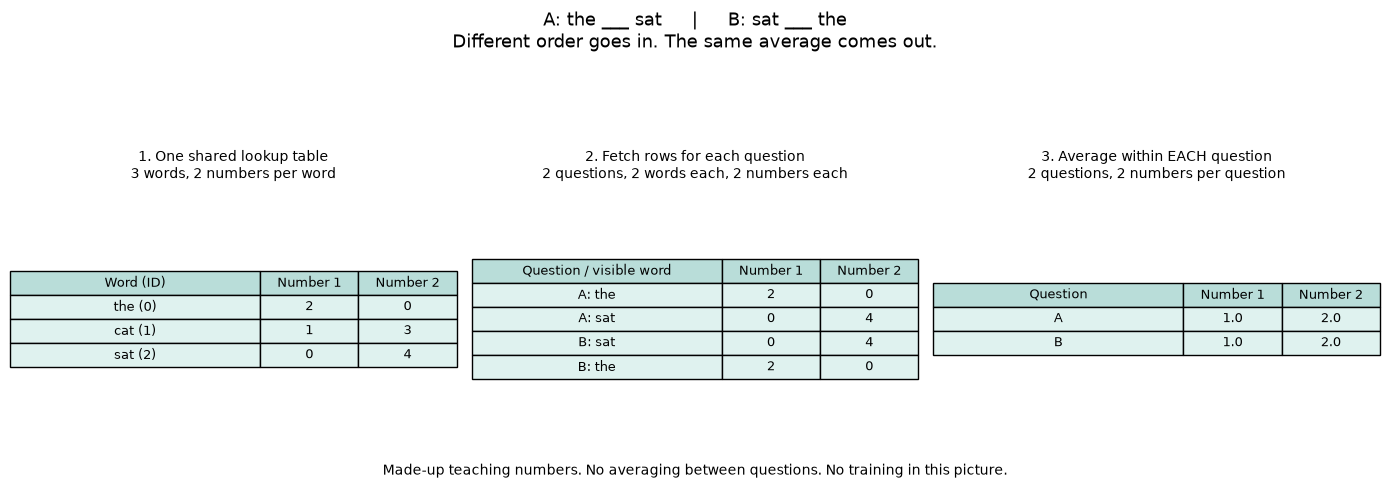

In [30]:
# ── 5 - See the rows before the shape letters ──
toy_table = torch.tensor([[2.0, 0.0], [1.0, 3.0], [0.0, 4.0]])
toy_ids = torch.tensor([[0, 2], [2, 0]])
toy_rows = torch.nn.functional.embedding(toy_ids, toy_table)
# [2 questions, 2 words, 2 numbers] -> [2, 2]: combine words WITHIN each question.
toy_averages = toy_rows.mean(dim=1)

print("Two questions, two visible word IDs each:\n", toy_ids)
print("One two-number row for each visible word:\n", toy_rows)
print("One averaged row per question:\n", toy_averages)
assert toy_rows.shape == (2, 2, 2)
assert torch.equal(toy_averages, torch.tensor([[1.0, 2.0], [1.0, 2.0]]))

toy_figure, toy_axes = plt.subplots(1, 3, figsize=(14, 5))
toy_panels = [
    (
        "1. One shared lookup table\n3 words, 2 numbers per word",
        ["Word (ID)", "Number 1", "Number 2"],
        [["the (0)", 2, 0], ["cat (1)", 1, 3], ["sat (2)", 0, 4]],
    ),
    (
        "2. Fetch rows for each question\n2 questions, 2 words each, 2 numbers each",
        ["Question / visible word", "Number 1", "Number 2"],
        [["A: the", 2, 0], ["A: sat", 0, 4],
         ["B: sat", 0, 4], ["B: the", 2, 0]],
    ),
    (
        "3. Average within EACH question\n2 questions, 2 numbers per question",
        ["Question", "Number 1", "Number 2"],
        [["A", *toy_averages[0].tolist()], ["B", *toy_averages[1].tolist()]],
    ),
]
for toy_axis, (title, columns, cells) in zip(toy_axes, toy_panels):
    toy_axis.axis("off")
    toy_axis.set_title(title, fontsize=10, pad=18)
    table = toy_axis.table(cellText=cells, colLabels=columns, loc="center",
                           cellLoc="center", colWidths=[0.56, 0.22, 0.22])
    table.auto_set_font_size(False)
    table.set_fontsize(9)
    table.scale(1, 2.4)
    for (row, column), cell in table.get_celld().items():
        cell.set_facecolor("#dff2ef" if row else "#b9ddd9")
toy_figure.suptitle("A: the ___ sat     |     B: sat ___ the\n"
                   "Different order goes in. The same average comes out.", fontsize=13)
toy_figure.text(0.5, 0.05, "Made-up teaching numbers. "
                "No averaging between questions. No training in this picture.", ha="center")
toy_figure.tight_layout(rect=(0, 0.1, 1, 0.85))
toy_directory = CHAPTER_DIRECTORY
toy_figure.savefig(toy_directory / "images" / "03a-lookup-tensor-structure.png", dpi=130)
plt.show()
plt.close(toy_figure)


### CBOW: follow the lookup and mean shapes

The code above prints the same two questions and redraws the picture.
`toy_table` is the registry's profile table, `toy_ids` holds the registry numbers,
`toy_rows` holds the retrieved profiles, and `toy_averages` keeps one pooled
profile per question. Pooling does not rewrite the individual token profiles.
Everything after the assertions draws the tables; it doesn't train a model.

| What we hold | Count it in plain English | Shape |
|---|---|---|
| Input IDs | 2 questions, 2 visible word IDs each | `[2, 2]` |
| Fetched rows | 2 questions, 2 words each, 2 numbers per word | `[2, 2, 2]` |
| Averaged rows | 2 questions, 2 numbers per question | `[2, 2]` |

People write `[B, C, D]` when they don't want to commit to particular counts:
**B** is the number of questions in the **batch**, **C** counts **context** words per question,
and **D** is the number of values in each word row (its embedding width).
The axes are places in that list, not the word IDs themselves.

After lookup, `.mean(dim=1)` means **average over the word rows in each question**.
PyTorch counts axes from zero: axis 0 is questions, axis 1 is words, axis 2 is numbers.
The word axis disappears, leaving one row per question: `[B, D]`.
The batch axis stays. Different questions aren't mixed together.

Now return to the real lesson data: **one question, four visible words, 32 numbers per
word**. Lookup gives `[1, 4, 32]`; averaging the four rows gives `[1, 32]`.
The operation is exactly the same as our little two-number example.

This is a **CBOW-style lookup preview**, not a shared dataset for all three models.
We build each model's training pairs in its own section below.

**Predict:** If we reverse those four visible words, will the averaged row change?
The next cell checks it with the actual embedding layer.


In [31]:
# ── Crude attempt: give every context word an equal vote ──
EMBEDDING_WIDTH = 32
probe_embedding = nn.Embedding(vocabulary_size, EMBEDDING_WIDTH)

# [N, 5] -> [3, 4]: inspect three rows, removing the hidden center column.
preview_contexts = window_ids[:3, [0, 1, 3, 4]]
# [3, 4] -> [1, 4]: retain the batch axis even when inspecting one question.
one_context = preview_contexts[:1]
# [1, 4] -> [1, 4]: reverse positions, not questions; mean should erase this change.
reversed_context = one_context.flip(dims=[1])
one_vectors = probe_embedding(one_context)
# [1, 4, 32] -> [1, 32]: pool only the four context rows.
original_mean = one_vectors.mean(dim=1)
reversed_mean = probe_embedding(reversed_context).mean(dim=1)

print("IDs:", one_context.tolist())
print("After lookup:", tuple(one_vectors.shape))
print("After context mean:", tuple(original_mean.shape))
print("Maximum difference after reversal:", (original_mean - reversed_mean).abs().max().item())

assert torch.allclose(original_mean, reversed_mean)


IDs: [[211, 33, 290, 185]]
After lookup: (1, 4, 32)
After context mean: (1, 32)
Maximum difference after reversal: 5.960464477539063e-08


### Shared lookup: why sensor profiles, and not a giant checklist?

A `[V, D]` embedding table can look like a dense layer expecting `V`
inputs. Here is the distinction: **we pass IDs to lookup, not V-wide inputs**.
`D` (also called `N`) is the number of values in the fetched row.

| Object in the three-word close-up | Values or contents | Shape |
|---|---|---|
| Stored embedding weights | All three two-number rows | `[3, 2]` |
| Actual input: one cat ID in a batch | `[1]` | `[1]` |
| Actual lookup output | `[[1, 3]]` | `[1, 2]` |
| One-hot input, **only for the equivalent calculation** | `[[0, 1, 0]]` | `[1, 3]` |

Multiplying that one-hot row by the table gives the same `[[1, 3]]`.
The one keeps the cat row; the zeros contribute nothing. `nn.Embedding`
selects the row directly, without constructing that checklist.

For one truly scalar input, `torch.tensor(1)` returns a `[2]` vector instead.
Wrapping it as `[1]` adds a batch axis, not more input features.
In real CBOW, `[B, 4]` means four IDs per question; lookup returns
`[B, 4, 32]`. The parameter table is still `[V, 32]`, not a per-word input.
`nn.Linear(1, D)` would use an ID's magnitude as a feature; it is not a
replacement for this row selection.

The checklist has two problems:

- **It's huge.** One box per word. GPT-2's tokenizer from 02B has 50,257 entries, so every
  token would be a row of 50,257 numbers with a single one in it. GPT-2's own input profiles have
  768 channels per token.
- **Every word is a stranger.** Any two different checklists differ in exactly two boxes. So
  `cat` sits exactly as far from `dog` as from `mat`. There's nowhere to write down
  "these two get used alike".

**Predict:** do our random profiles fix the second problem already?


In [32]:
# ── Why sensor profiles, and not a giant one-hot checklist? ──
scalar_cat_id = torch.tensor(1, dtype=torch.long)
one_cat_batch = scalar_cat_id.unsqueeze(0)
scalar_cat_row = nn.functional.embedding(scalar_cat_id, toy_table)
lookup_cat_row = nn.functional.embedding(one_cat_batch, toy_table)
one_hot_cat = nn.functional.one_hot(one_cat_batch, num_classes=3).to(toy_table.dtype)
checklist_cat_row = one_hot_cat @ toy_table
assert scalar_cat_row.shape == (2,)
assert lookup_cat_row.shape == checklist_cat_row.shape == (1, 2)
assert torch.equal(lookup_cat_row, torch.tensor([[1., 3.]]))
assert torch.equal(lookup_cat_row, checklist_cat_row)
print("Stored table:", tuple(toy_table.shape), "= [V, D] weights")
print("Scalar ID -> row:", tuple(scalar_cat_id.shape), "->", tuple(scalar_cat_row.shape))
print("Actual ID batch:", one_cat_batch.tolist(), tuple(one_cat_batch.shape))
print("Actual lookup:  ", lookup_cat_row.tolist(), tuple(lookup_cat_row.shape))
print("One-hot check:  ", one_hot_cat.tolist(), tuple(one_hot_cat.shape))
print("Same result:    ", checklist_cat_row.tolist(), tuple(checklist_cat_row.shape))

checklists = torch.eye(vocabulary_size)
random_rows = probe_embedding.weight.detach()


def checklist_gap(word_a, word_b):
    return (checklists[stoi[word_a]] - checklists[stoi[word_b]]).norm().item()


def row_similarity(rows, word_a, word_b):
    return torch.cosine_similarity(rows[stoi[word_a]], rows[stoi[word_b]], dim=0).item()


print(f"\nOne checklist: {vocabulary_size} boxes. One sensor profile: {EMBEDDING_WIDTH} channels.")
for word_a, word_b in [("cat", "dog"), ("cat", "mat")]:
    print(f"{word_a} vs {word_b:<10}  checklist gap {checklist_gap(word_a, word_b):.3f}   "
          f"random-row similarity {row_similarity(random_rows, word_a, word_b):+.3f}")

assert checklist_gap("cat", "dog") == checklist_gap("cat", "mat")


Stored table: (3, 2) = [V, D] weights
Scalar ID -> row: () -> (2,)
Actual ID batch: [1] (1,)
Actual lookup:   [[1.0, 3.0]] (1, 2)
One-hot check:   [[0.0, 1.0, 0.0]] (1, 3)
Same result:     [[1.0, 3.0]] (1, 2)

One checklist: 1202 boxes. One sensor profile: 32 channels.
cat vs dog         checklist gap 1.414   random-row similarity +0.055
cat vs mat         checklist gap 1.414   random-row similarity +0.127


First the code compared a scalar ID, a one-word batch, and the explicit
one-hot calculation. Same selected row, different input shapes. Only the
last calculation needed a vocabulary-wide checklist.

The remaining code compared different words. The checklist gaps tie exactly for every pair: the checklist cannot say "these two are alike".
Random sensor profiles give different scores, but those scores are luck, not learned meaning.
The rows have done job one (compact features). Job two (useful shared features) needs practice.

We already have real stories, but that is not a guarantee about `cat`'s nearest neighbour.
Section 9 prints the actual neighbours without insisting that `dog` must win.
Section 13 uses more text, named inspection groups, and held-out stories to check more carefully.


### CBOW: the same mean with `EmbeddingBag`

We've deliberately done two separate things: fetch the word rows, then average them.
`nn.EmbeddingBag(..., mode="mean")` does both in one call.
Give it the same table and the same visible word IDs, and it should return the same average.
The next cell checks that, rather than asking you to take the shortcut on trust.

We'll keep the two steps separate in CBOW so you can still see the fetched rows before
they get combined. The compact layer is handy later, including when questions contain
different numbers of visible words.


In [33]:
# ── Where EmbeddingBag fits ──
embedding_bag = nn.EmbeddingBag(
    vocabulary_size,
    EMBEDDING_WIDTH,
    mode="mean",
)
with torch.no_grad():
    embedding_bag.weight.copy_(probe_embedding.weight)

# [3, 4, 32] -> [3, 32]: average each question's clues; EmbeddingBag fuses this same job.
manual_means = probe_embedding(preview_contexts).mean(dim=1)
bag_means = embedding_bag(preview_contexts)

print("Manual mean shape:", tuple(manual_means.shape))
print("EmbeddingBag shape:", tuple(bag_means.shape))
print("Maximum difference:", (manual_means - bag_means).abs().max().item())
assert torch.allclose(manual_means, bag_means)


Manual mean shape: (3, 32)
EmbeddingBag shape: (3, 32)
Maximum difference: 0.0


### 6A - CBOW data: neighbours in, middle word out

The windows so far are **raw material**, not one universal training dataset.
Only now do we choose what to hide and what to show:

```text
one raw window:  the  sleepy  cat  sat  on
CBOW input:    [the, sleepy,      sat, on]
CBOW answer:                 cat
```

Each window makes **one** question. `cbow_contexts` holds the four clues and
`cbow_targets` holds the middle word. `cbow_dataloader` batches these particular
pairs. Skip-gram and the writer will build their own pairs directly from `window_ids`,
not reuse this loader.

**Predict:** For N windows, do we get N answers or 4N? What shape should one
batch have? Inputs `[B, 4]`, answers `[B]`.


In [34]:
# ── 6A - CBOW data: neighbours -> middle word ──
# Two [N, 2] slices -> [N, 4]: join left/right clues without the center answer.
cbow_contexts = torch.cat(
    [window_ids[:, :CONTEXT_RADIUS], window_ids[:, CONTEXT_RADIUS + 1:]],
    dim=1,
)
# [N, 5] -> [N]: one center answer per row, in the same row order.
cbow_targets = window_ids[:, CONTEXT_RADIUS]
cbow_dataloader = make_dataloader(cbow_contexts, cbow_targets)
cbow_batch_contexts, cbow_batch_targets = next(iter(cbow_dataloader))

print("CBOW: neighbours -> middle word")
print("Questions:", len(cbow_contexts))
print("Batch inputs:", tuple(cbow_batch_contexts.shape))
print("Batch answers:", tuple(cbow_batch_targets.shape))
print(
    "Illustrated cat-document pair:",
    [itos[index] for index in cbow_contexts[-3].tolist()],
    "->", itos[cbow_targets[-3]],
)

assert cbow_contexts.shape == (len(window_ids), 2 * CONTEXT_RADIUS)
assert cbow_targets.shape == (len(window_ids),)
assert torch.equal(cbow_targets, window_ids[:, CONTEXT_RADIUS])
assert len(cbow_batch_contexts) == len(cbow_batch_targets)


CBOW: neighbours -> middle word
Questions: 94512
Batch inputs: (512, 4)
Batch answers: (512,)
Illustrated cat-document pair: ['the', 'sleepy', 'sat', 'on'] -> cat


### CBOW: check the question and answer

Before putting this in a class, check what goes in, what comes out, and which answer we grade:

| Question | CBOW answer |
|---|---|
| Input IDs | `[B, C]`: several context positions |
| Target IDs | `[B]`: one center word per lesson |
| Word scores (logits) | `[B, V]`: one set of word scores per example |
| Which answer goes with which scores? | logits row `b` versus center ID `b` |
| What gets combined | Which context rows appeared |
| What gets lost | Context order, because changing the order doesn't change the average |

**Predict:** Are we asking for one answer word or several? Where do the four context
positions get combined into one vector? Follow `[B, C] -> [B, C, D] -> [B, D]` before reading
the class below.

### 6B - CBOW model: change the guessing game, not the training routine

Each model still has two familiar jobs:

- `__init__` sets up the trainable layers.
- `forward` turns a batch of input IDs into word scores, called **logits**.

The shared loop needs one more answer: **which correct word goes with each set of scores?**
For CBOW, that's one missing word per example. For the encoder-decoder later, it's several
answer words in order. We should not need a new optimizer loop just because the answer got longer.

`TrainableLanguageModel` keeps that bookkeeping and `fit_language_model` in one place.
You still provide the data loader, loss function, and optimizer. The model chooses its layers.
Its `targets_for_loss` method picks the answers to grade; the encoder-decoder changes that
method to skip the start marker, but keeps the same training loop.

```text
input IDs
-> model's forward
-> word scores [..., vocabulary]
-> put the correct answer beside each set of scores
-> flatten [B, T, V] to [B*T, V] and answers [B, T] to [B*T]
   # Same example-then-time order on both sides; each score keeps its answer.
-> cross-entropy loss
```

Here is CBOW's part of that shared routine:

```text
context IDs [B, C]
-> fetch rows [B, C, D]
-> average them [B, D]
-> hidden features [B, D/2]
-> word scores [B, V]
```

The base class handles practice. The subclass decides how to make a guess.


**Experiment state - CBOW:** fresh random 32-number rows, four clue IDs per
question, mean pooling, and separate prediction layers. Training updates both
rows and predictor. The center answer is not another input lookup.
Reversing the clues cannot change their mean: useful rows do not restore
order discarded by pooling.


In [35]:
# ── 6B - CBOW model ──
class TrainableLanguageModel(nn.Module):
    """Share target alignment and optimization across language objectives."""

    def targets_for_loss(self, target_ids):
        # Which answers should the guesses be marked against?
        # CBOW and Skip-gram: the loader's answers already line up one-to-one
        # with the guesses, so hand them back unchanged.
        # A subclass overrides this when guesses and answers are offset
        # (the encoder-decoder drops its <bos> start marker).
        return target_ids

    def training_loss(self, input_ids, target_ids, loss_function):
        # 1. Make the guesses. self(...) runs the subclass's forward().
        #    target_ids rides along because the encoder-decoder needs it for
        #    teacher forcing; CBOW and Skip-gram simply ignore it.
        #      CBOW / Skip-gram scores: [B, V]     one guess per lesson
        #      Encoder-decoder scores:  [B, T, V]  one guess per output step
        logits = self(input_ids, target_ids)

        # 2. Pick the answers those guesses should be checked against.
        expected_ids = self.targets_for_loss(target_ids)

        # 3. Cross-entropy wants a flat pile of guesses [N, V] and a matching
        #    flat pile of answers [N]. For CBOW nothing changes (N = B).
        #    For the encoder-decoder every step becomes its own row
        #    (N = B * T), so each step gets marked separately.
        #    Both reshapes keep the SAME row-major order: example 0's
        #    steps, then example 1's steps. Never transpose only one side.
        flat_logits = logits.reshape(-1, logits.shape[-1])
        flat_targets = expected_ids.reshape(-1)

        # 4. One number: on average, how surprised was the model by the right answers?
        return loss_function(flat_logits, flat_targets)

    def fit_language_model(self, dataloader, loss_function, optimizer, epochs):
        history = []

        for _ in range(epochs):
            self.train()
            total_loss = 0.0

            for input_batch, target_batch in dataloader:
                optimizer.zero_grad()
                loss = self.training_loss(input_batch, target_batch, loss_function)
                loss.backward()
                optimizer.step()
                # loss is the AVERAGE over this batch. Times the batch size turns it
                # back into a batch TOTAL, so a short last batch (say 2 lessons
                # instead of 5) counts for 2 lessons, not as much as a full batch.
                total_loss += loss.item() * len(input_batch)

            # Grand total / number of lessons = true average loss per lesson this epoch.
            history.append(total_loss / len(dataloader.dataset))

        return history


class CBOW(TrainableLanguageModel):
    def __init__(self, vocabulary_size, embedding_width):
        super().__init__()
        # One learned sensor profile per word; rows store the profiles.  [V, D]
        self.embedding = nn.Embedding(vocabulary_size, embedding_width)
        # A small "thinking" layer that squeezes the row down to D/2 features.
        self.hidden = nn.Linear(embedding_width, embedding_width // 2)
        # ReLU zeroes negatives, so the two layers can't collapse into one straight line.
        self.activation = nn.ReLU()
        # One score per vocabulary word: "how likely is this the hidden word?"
        self.output = nn.Linear(embedding_width // 2, vocabulary_size)

    def forward(self, context_ids, target_ids=None):
        # target_ids is unused here; it's in the signature so the shared
        # training loop can call every model the same way.
        # B is the current batch (at most 512), D=32 here; V is printed above.

        # context_ids: the four clue words around each gap, as IDs.   [B, 4]
        # e.g. "the sleepy ___ sat on" -> [the, sleepy, sat, on]
        # Retrieve the stored profile for each clue word.                     [B, 4, D]
        token_vectors = self.embedding(context_ids)

        # Average the four rows into one "gist of the clues" row.     [B, D]
        # This is the "bag" in bag of words: word order is lost here.
        pooled_context = token_vectors.mean(dim=1)

        # Projection [B, D] -> [B, D/2]: mix the gist into fewer learned features.
        hidden_features = self.activation(self.hidden(pooled_context))

        # Projection [B, D/2] -> [B, V]: one score per possible missing word.
        # These are raw scores (logits); cross-entropy turns them into chances.
        return self.output(hidden_features)


### CBOW: trace one batch before training

Call `model(batch)`, not `model.forward(batch)`. PyTorch calls `forward` for us and also runs
the surrounding framework machinery, including hooks.

We get `[batch, vocabulary]`: one row of possible-word scores for each practice question.
The loss will compare each row with the ID of its correct answer.

In [36]:
# ── Trace one untrained batch before optimizing anything ──
torch.manual_seed(SEED)
model = CBOW(vocabulary_size, EMBEDDING_WIDTH)
untrained_logits = model(cbow_batch_contexts)


def word_probe(logits, expected_word, words=itos):
    """Keep probability, rank, and the actual shortlist; never force the answer."""
    # [V] -> [V]: softmax changes scores to shares without changing the word axis.
    chances = logits.detach().softmax(dim=-1)
    expected_id = words.index(expected_word)
    rank = int((chances > chances[expected_id]).sum()) + 1
    top = chances.topk(5)
    return {
        "probability": chances[expected_id].item(),
        "rank": rank,
        "top5": [(words[index], round(chance, 4))
                 for index, chance in zip(top.indices.tolist(), top.values.tolist())],
    }


def report_probe(label, before, after):
    print(f"{label}: correct-word share {before['probability']:.3%} -> "
          f"{after['probability']:.3%}; rank {before['rank']} -> {after['rank']}")
    print("  Before top 5:", before["top5"])
    print("  After top 5: ", after["top5"])
    probability_change = "increased" if after["probability"] > before["probability"] else "decreased"
    rank_change = "improved" if after["rank"] < before["rank"] else (
        "worsened" if after["rank"] > before["rank"] else "stayed the same")
    print(f"  Probability {probability_change}; rank {rank_change}. "
          + ("The expected word is top-ranked." if after["rank"] == 1 else "Not the first guess."))


# [3, 5] -> [3, 4]: the same missing-center job, now on the familiar cat document.
cat_contexts = cat_window_ids[:, [0, 1, 3, 4]]
with torch.inference_mode():
    cat_before_logits = model(cat_contexts)
    cbow_before = {word: word_probe(cat_before_logits[row], word)
                   for row, word in enumerate(("cat", "sat", "on"))}

print("Input cbow_contexts:", tuple(cbow_batch_contexts.shape))
print("Vocabulary logits:", tuple(untrained_logits.shape))
assert untrained_logits.shape == (len(cbow_batch_contexts), vocabulary_size)


Input cbow_contexts: (512, 4)
Vocabulary logits: (512, 1202)


## 7 - CBOW: train and check with its own loader

Cross-entropy checks how much probability the model gives the correct word compared with the
alternatives. It takes raw scores and does the log-softmax calculation itself. Don't add a
separate softmax first: that repeats work and makes the calculation less stable.

Every practice step follows the same order:

1. `zero_grad()` clears feedback left over from the previous step.
2. `training_loss(...)` makes the guesses and lines them up with the correct answers.
3. `backward()` works out how each participating weight affected the loss.
4. `step()` lets the optimizer adjust those weights.

The loop doesn't need to know whether we averaged word rows or passed a note through a GRU.
That is the model's job. It does need to put the model in training mode, count loss fairly
across batches, and keep using the same optimizer across epochs.

Calling `model.fit_language_model(...)` uses the method inherited from the base class.
Inside it, `self` is still our actual model, so its own `forward` and `targets_for_loss`
methods do the guessing and answer selection.

Keep PyTorch's `train()` separate: it switches training mode. Despite its name, it does not
run the practice loop.

In [37]:
# ── 7 - One fit loop should survive the model swap ──
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.008)
cbow_started = time.perf_counter()
losses = model.fit_language_model(
    cbow_dataloader,
    criterion,
    optimizer,
    epochs=10,
)
cbow_seconds = time.perf_counter() - cbow_started

print(f"Loss: {losses[0]:.4f} -> {losses[-1]:.4f}")
print(f"CBOW: {cbow_seconds:.1f}s on one CPU thread (10 epochs)")
with torch.inference_mode():
    cat_after_logits = model(cat_contexts)
    for row, word in enumerate(("cat", "sat", "on")):
        report_probe(f"CBOW missing {word!r}", cbow_before[word],
                     word_probe(cat_after_logits[row], word))


Loss: 5.1225 -> 3.4422
CBOW: 16.1s on one CPU thread (10 epochs)
CBOW missing 'cat': correct-word share 0.076% -> 0.028%; rank 732 -> 114
  Before top 5: [('school', 0.0016), ('grab', 0.0015), ('open', 0.0014), ('followed', 0.0014), ('good', 0.0014)]
  After top 5:  [('and', 0.2965), ('on', 0.1239), ('in', 0.0782), ('to', 0.0723), ('down', 0.048)]
  Probability decreased; rank improved. Not the first guess.
CBOW missing 'sat': correct-word share 0.090% -> 0.181%; rank 398 -> 90
  Before top 5: [('school', 0.0016), ('grab', 0.0015), ('chicken', 0.0015), ('round', 0.0015), ('house', 0.0014)]
  After top 5:  [('<unk>', 0.0888), ('to', 0.0883), ('and', 0.0611), ('in', 0.0414), ('up', 0.0277)]
  Probability increased; rank improved. Not the first guess.
CBOW missing 'on': correct-word share 0.096% -> 87.020%; rank 304 -> 1
  Before top 5: [('guilty', 0.0016), ('happen', 0.0015), ('clapped', 0.0015), ('color', 0.0014), ('find', 0.0014)]
  After top 5:  [('on', 0.8702), ('and', 0.026), ('in',

### CBOW: the loss fell. Did it learn our particular blank?

Equal chance for every word gives cross-entropy `log(V)`, our uniform-guess reference line.
The first epoch's average is **not** the untrained loss: weights changed throughout that epoch.
The cat probes above, by contrast, compare the exact same inputs at initialization and after
training. Read expected-word probability, rank, and both shortlists together.

On the measured CPU run, **13,765 documents / 149,572 tokens / 94,512 windows / 1,202
vocabulary entries** replaced the old hand-written-only training set. The single appended
document supplies just three of those windows. Introductory training took **66.9 seconds**
and the entire cached Python lesson **199.5 seconds**, including the later comparison and
visuals. Times are measurements, not portable promises.

| CBOW blank | Correct-word share before -> after | Rank before -> after |
|---|---|---|
| `cat` | 0.076% -> 0.028% | 732 -> 114 |
| `sat` | 0.090% -> 0.181% | 398 -> 90 |
| `on` | 0.096% -> 87.020% | 304 -> 1 |

The `cat` rank improved while its probability fell: **better rank does not mean greater
confidence in the correct word**. For CBOW, `sat` probability rose, but it still was not first.
The strongest exact payoff is **cat sat ___ the mat**: `on` moved from rank **304 to 1**
and from **0.096% to 87.020%** probability. More real-text fitting is not guaranteed recall
of every word in our one cat document.

CBOW's question is **the sleepy ___ sat on**: it can see clues on both sides.
The writer later gets **the sleepy cat** and must predict **sat** without future clues.
Do not compare their raw losses as if they answered the same question.
Lower training loss proves better fitting, not held-out generalization or guaranteed recall
of the single appended sentence. We leave that sentence at its ordinary one-document weight.


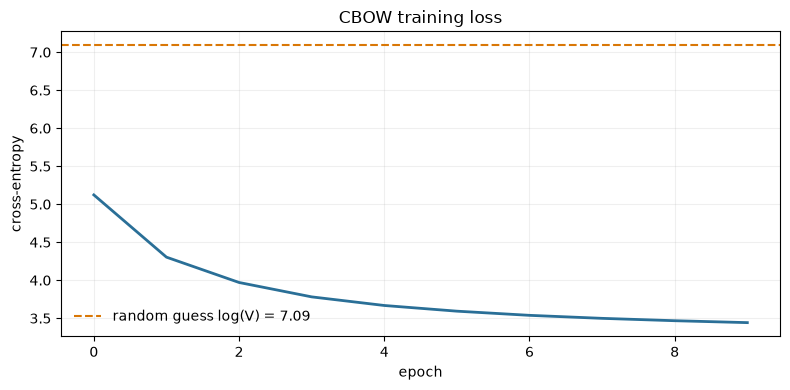

Random-guess baseline: 7.0917
Final training loss: 3.4422


In [38]:
# ── A falling loss is necessary evidence, not the whole story ──
random_guess_loss = math.log(vocabulary_size)

fig, axis = plt.subplots(figsize=(8, 4))
axis.plot(losses, color="#2a6f97", linewidth=2)
axis.axhline(
    random_guess_loss,
    color="#d97706",
    linestyle="--",
    label=f"random guess log(V) = {random_guess_loss:.2f}",
)
axis.set(title="CBOW training loss", xlabel="epoch", ylabel="cross-entropy")
axis.legend(frameon=False)
axis.grid(alpha=0.2)
plt.tight_layout()
plt.show()
plt.close(fig)

print(f"Random-guess baseline: {random_guess_loss:.4f}")
print(f"Final training loss: {losses[-1]:.4f}")
assert losses[-1] < losses[0]
assert losses[-1] < random_guess_loss


## 8 - CBOW: follow feedback to the rows we fetched

Return to the exact illustrated question: **the sleepy ___ sat on**, answer
**cat**. Four fixed IDs fetch four rows. Those rows feed the predictor, but
they are also entries in the model's **trainable embedding weight table**.

```text
unchanged IDs -> fetched trainable rows -> predictor -> scores -> loss
                         ^                   ^
                         +-- feedback -------+
```

`backward()` calculates how the loss depends on the stored numbers; it doesn't
edit the integer addresses. `step()` changes the stored numbers. A second
lookup using the same IDs then fetches the updated rows. If an ID appears more
than once, its row receives feedback from each use.

We'll use a **copy** of the trained model so this close-up doesn't change the
later experiments. A fresh plain SGD optimizer, with no momentum or weight
decay, makes the comparison exact: rows we didn't fetch stay unchanged.
With other optimizer settings, old momentum or weight decay can also move rows;
a zero gradient from this question is a different claim.

The output layer is separate: it scores **every possible answer**, so it doesn't
follow the input table's fetched-row rule. In particular, `cat` is the answer
we check, not an extra input row we opened.

**Predict:** which input rows should change: the four clues, only `cat`, or
every word? Should any ID change? Check the snapshots, not just the gradients.


In [39]:
# ── 8 - The same IDs fetch updated rows after one optimizer step ──
gradient_model = deepcopy(model)
gradient_contexts = cat_contexts[:1].clone()
gradient_targets = torch.tensor([stoi["cat"]], dtype=torch.long)
saved_context_ids = gradient_contexts.clone()
saved_target_ids = gradient_targets.clone()
rows_before_step = gradient_model.embedding.weight.detach().clone()
output_before_step = gradient_model.output.weight.detach().clone()
gradient_optimizer = torch.optim.SGD(gradient_model.parameters(), lr=0.1)
gradient_optimizer.zero_grad()
gradient_loss = gradient_model.training_loss(gradient_contexts, gradient_targets, criterion)
gradient_loss.backward()

gradient_norms = gradient_model.embedding.weight.grad.norm(dim=1)
used_ids = set(gradient_contexts.reshape(-1).tolist())
rows_with_gradient = set(gradient_norms.nonzero().flatten().tolist())
gradient_optimizer.step()
changed_rows = (gradient_model.embedding.weight.detach() != rows_before_step).any(dim=1)
changed_ids = set(changed_rows.nonzero().flatten().tolist())

assert rows_with_gradient == changed_ids == used_ids
assert stoi["cat"] not in changed_ids
assert torch.equal(gradient_contexts, saved_context_ids)
assert torch.equal(gradient_targets, saved_target_ids)
assert not gradient_contexts.requires_grad and gradient_contexts.grad is None
assert not torch.equal(gradient_model.output.weight.detach(), output_before_step)
assert torch.equal(
    gradient_model.embedding(gradient_contexts).detach(),
    gradient_model.embedding.weight.detach()[saved_context_ids],
)
print("Unchanged input IDs:", gradient_contexts.tolist(), "answer ID:", gradient_targets.tolist())
print("Fetched rows / changed rows:",
      [itos[index] for index in sorted(used_ids)], [itos[index] for index in sorted(changed_ids)])
first_id = gradient_contexts[0, 0].item()
print(f"{itos[first_id]!r} row, first three values before:", rows_before_step[first_id, :3].tolist())
print("Same ID, values fetched after:", gradient_model.embedding(gradient_contexts)[0, 0, :3].detach().tolist())
print("Takeaway: stored embedding weights and predictor weights changed; no input or answer ID did.")


Unchanged input IDs: [[1, 1200, 304, 22]] answer ID: [164]
Fetched rows / changed rows: ['the', 'on', 'sat', 'sleepy'] ['the', 'on', 'sat', 'sleepy']
'the' row, first three values before: [0.27715864777565, -0.4848954975605011, -0.4095971882343292]
Same ID, values fetched after: [0.3005733788013458, -0.5222456455230713, -0.4456244707107544]
Takeaway: stored embedding weights and predictor weights changed; no input or answer ID did.


The copied model keeps the main training run untouched. We saved the IDs and
weights before the step, then checked them separately afterward: the addresses
match exactly, the four fetched rows have changed, and the predictor changed too.
The final lookup checks that those same addresses now fetch the updated rows.

## 9 - CBOW: inspect the learned neighbours

The rows we trained are right there in `model.embedding.weight`, a table shaped `[V, D]`.
Let's fetch a word's row and ask which other rows point in a similar direction.
That's **cosine similarity**: compare direction rather than letting a longer vector win
just because it's longer.

Before looking:

- `detach()` keeps this inspection out of the training calculation.
- `cpu()` moves GPU data back if needed; we're already on CPU here.
- Divide each row by its length to make its length one.

Then we can compare our chosen word with every row at once:

```text
all normalized rows @ one normalized word row
```

Leave the chosen word out of its own results; of course it matches itself.
Leave `<unk>` out too: it was trained as a catch-all for many discarded words,
not as one readable word whose meaning we can inspect.

Now check the neighbours, not just the numbers. Do any relationships make sense for the
questions we trained on? With this little text, don't expect a ready-made dictionary.
This is where we inspect what the guessing game taught, not declare that every nearby
word is a synonym.

In [40]:
# ── 9 - The learned embedding weights are the vectors ──
embedding_weights = model.embedding.weight.detach().cpu()
# [V, 32] -> [V, 1]: keep a singleton feature axis so division normalizes EACH word row.
embedding_norms = embedding_weights.norm(dim=1, keepdim=True).clamp_min(1e-12)
normalized_embeddings = embedding_weights / embedding_norms


def most_similar(word, top_k=4):
    if word not in stoi:
        return f"'{word}' is not in the vocabulary"

    similarities = normalized_embeddings @ normalized_embeddings[stoi[word]]
    similarities = similarities.clone()
    similarities[stoi[word]] = -1
    similarities[stoi["<unk>"]] = -1
    neighbour_ids = similarities.topk(min(top_k, vocabulary_size - 2)).indices
    return [
        (itos[index], round(similarities[index].item(), 3))
        for index in neighbour_ids.tolist()
    ]


for word in ["cat", "dog", "mat", "sat"]:
    print(f"{word:>12} -> {most_similar(word)}")


         cat -> [('tommy', 0.642), ('swan', 0.615), ('lady', 0.601), ('fish', 0.579)]
         dog -> [('duck', 0.706), ('camera', 0.589), ('people', 0.58), ('spider', 0.577)]
         mat -> [('sitting', 0.574), ('curious', 0.55), ('quiet', 0.526), ('friendly', 0.516)]
         sat -> [('wall', 0.65), ('hopped', 0.601), ('ground', 0.573), ('lay', 0.572)]


### CBOW: draw what the rows learned

Each word has 32 numbers. We have only two axes on the page.
Select the cat-probe words and common words, subtract their feature-wise center, and use SVD
to find two PCA directions. Transposing those directions makes two projection columns:
`[words, 32] @ [32, 2] -> [words, 2]`.

Thirty directions are absent from this sketch. Nearby dots need not be nearby in the full
table; check the cosine scores too. This small map is not a semantic-quality benchmark.


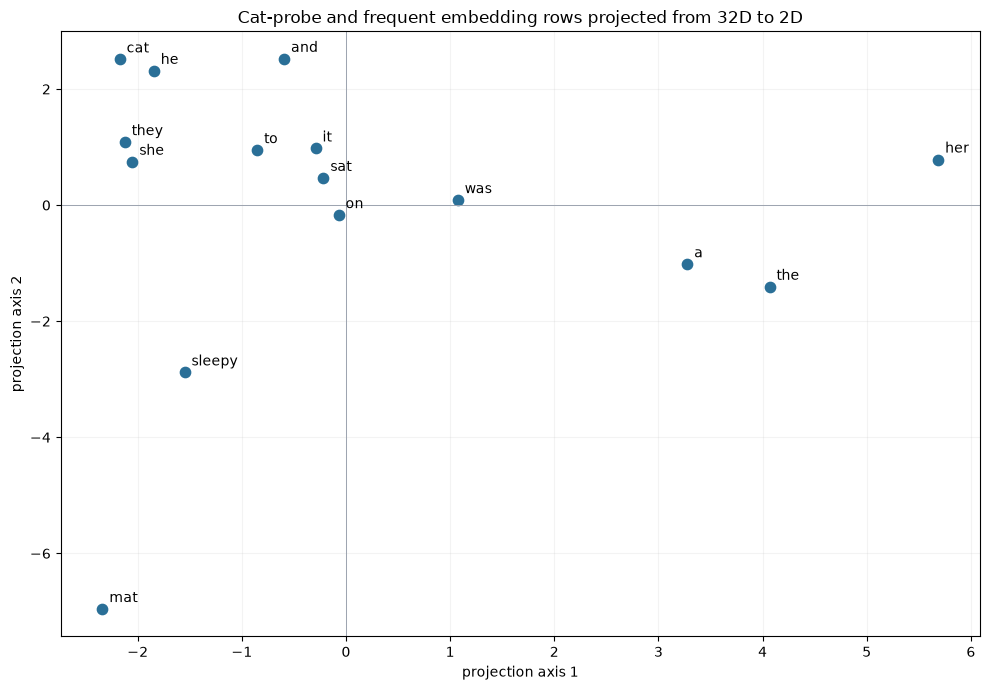

In [41]:
# ── A 2D projection is a map, not the territory ──
# [V, 32] -> [visible words, 32]: keep the running example beside common words.
visible_words = list(dict.fromkeys(tokenize(CAT_PROBE) + [w for w, _ in counts.most_common(10)]))
visible_ids = torch.tensor([stoi[word] for word in visible_words])
visible_vectors = embedding_weights[visible_ids]
# [words, 32] -> [1, 32]: one center per feature, broadcast back across words.
centered = visible_vectors - visible_vectors.mean(dim=0, keepdim=True)
_, _, right_singular_vectors = torch.linalg.svd(centered, full_matrices=False)
# [2, 32] -> [32, 2]: turn two PCA directions into columns; project [words, 32] -> [words, 2].
coordinates = centered @ right_singular_vectors[:2].T

fig, axis = plt.subplots(figsize=(10, 7))
axis.scatter(coordinates[:, 0], coordinates[:, 1], color="#2a6f97", s=55)
for point, token_id in zip(coordinates, visible_ids.tolist()):
    axis.annotate(itos[token_id], point, xytext=(5, 5), textcoords="offset points")
axis.axhline(0, color="#9ca3af", linewidth=0.7)
axis.axvline(0, color="#9ca3af", linewidth=0.7)
axis.set(
    title="Cat-probe and frequent embedding rows projected from 32D to 2D",
    xlabel="projection axis 1",
    ylabel="projection axis 2",
)
axis.grid(alpha=0.15)
plt.tight_layout()
plt.show()
plt.close(fig)


## 10 - Skip-gram: guess neighbours from the center

CBOW asks:

```text
[left, left, right, right] -> center
```

What if we uncover the middle word and cover one neighbour instead?

```text
center -> left neighbour
center -> left neighbour
center -> right neighbour
center -> right neighbour
```

That is **Skip-gram**. We don't need new text or a new vocabulary. Each old window gives us
four new practice questions, all using the same center word but a different neighbour as the answer.
The loader still hands over `(input IDs, target IDs)`. What those IDs stand for has changed.

### 10A - Prepare Skip-gram's own pairs and loader

```text
raw window: [the, sleepy, cat, sat, on]
input       answer
cat      -> the
cat      -> sleepy
cat      -> sat
cat      -> on
```

These are **four independent questions**, not one input with a four-word answer.
We start again from `window_ids`. `repeat_interleave` repeats each center four times;
`reshape(-1)` lists its neighbours in the same order, keeping every pair aligned.
`skipgram_dataloader` contains no CBOW input/answer pairs.

**Predict:** With `N` windows and four neighbours each, how many practice questions do we get? `4N`.

In [42]:
# ── 10A - Skip-gram data: middle word -> one neighbour ──
# Each raw window supplies one center and all its neighbours.
skipgram_centers = window_ids[:, CONTEXT_RADIUS]
# [N, 2] plus [N, 2] -> [N, 4]: keep each window's neighbours in left-to-right order.
skipgram_neighbours = torch.cat(
    [window_ids[:, :CONTEXT_RADIUS], window_ids[:, CONTEXT_RADIUS + 1:]],
    dim=1,
)
neighbours_per_window = skipgram_neighbours.shape[1]
# [N] -> [4N]: repeat each center four times BEFORE moving to the next window.
skipgram_inputs = skipgram_centers.repeat_interleave(neighbours_per_window)
# [N, 4] -> [4N]: row-major flattening keeps each answer aligned with its repeated center.
skipgram_targets = skipgram_neighbours.reshape(-1)
skipgram_dataloader = make_dataloader(skipgram_inputs, skipgram_targets)
skipgram_batch_inputs, skipgram_batch_targets = next(iter(skipgram_dataloader))

print("Skip-gram: middle word -> ONE neighbour per question")
print("Questions:", len(skipgram_inputs))
print("Batch inputs:", tuple(skipgram_batch_inputs.shape))
print("Batch answers:", tuple(skipgram_batch_targets.shape))
print("Pairs from the illustrated cat window:")
for center, neighbour in zip(
    skipgram_inputs[-3 * neighbours_per_window:-2 * neighbours_per_window],
    skipgram_targets[-3 * neighbours_per_window:-2 * neighbours_per_window],
):
    print("   ", itos[center], "->", itos[neighbour])

assert skipgram_inputs.shape == (len(window_ids) * neighbours_per_window,)
assert skipgram_targets.shape == skipgram_inputs.shape
assert torch.equal(
    # [4N] -> [N, 4]: reconstruct groups to check alignment, not mix examples.
    skipgram_inputs.reshape(len(window_ids), neighbours_per_window),
    # [N] -> [N, 1] -> [N, 4]: broadcast a center beside each of its own neighbours.
    skipgram_centers[:, None].expand_as(skipgram_neighbours),
)
assert torch.equal(
    # [4N] -> [N, 4]: the flattened answers must reconstruct the original neighbour rows.
    skipgram_targets.reshape_as(skipgram_neighbours), skipgram_neighbours,
)
assert len(skipgram_batch_inputs) == len(skipgram_batch_targets)


Skip-gram: middle word -> ONE neighbour per question
Questions: 378048
Batch inputs: (512,)
Batch answers: (512,)
Pairs from the illustrated cat window:
    cat -> the
    cat -> sleepy
    cat -> sat
    cat -> on


### Skip-gram: check the question and answer

The loader still hands over two tensors. This time the question is one word ID, not four:

| What to check | Skip-gram |
|---|---|
| Input IDs | `[B]`: one center ID per question |
| Correct answers | `[B]`: one neighbour ID per question |
| Word scores | `[B, V]`: one set of scores per question |
| What we grade | Scores in row `b` against neighbour ID `b` |
| What the model sees | Which center word we showed it |
| What it doesn't see | Whether this answer came from the left, right, nearer, or farther away |

**Predict:** Why did the extra context dimension disappear? Why can the same question have
several different correct neighbours? The shared loop still works because each set of
scores has an answer beside it, not because CBOW and Skip-gram ask the same question.

### 10B - Skip-gram: define, train, and check neighbour guesses

CBOW fetched several rows and averaged them. Skip-gram fetches just the center row.
There is nothing to average. The remaining layers still turn their input into word scores:

```text
center IDs [B]
-> fetch rows [B, D]
-> hidden features [B, D/2]
-> word scores [B, V]
```

Keep the same base class, loader helper, loss, and practice loop.
Here we score every word in the vocabulary so the whole path stays visible.
On much larger text collections, Word2Vec usually saves work with negative sampling or
hierarchical softmax rather than scoring every possible word.


**Experiment state - Skip-gram:** a new model with its own random 32-number
rows, not a continuation of CBOW. One center ID predicts one neighbour per
card. This resembles the earlier learning game, except text now supplies
the cards. Rows and prediction layers learn together.


In [43]:
# ── The model swap is smaller than the objective swap ──
class SkipGram(TrainableLanguageModel):
    def __init__(self, vocabulary_size, embedding_width):
        super().__init__()
        self.embedding = nn.Embedding(vocabulary_size, embedding_width)
        self.hidden = nn.Linear(embedding_width, embedding_width // 2)
        self.activation = nn.ReLU()
        self.output = nn.Linear(embedding_width // 2, vocabulary_size)

    # Same layers as CBOW. The only change is what goes in: one word, not four.
    def forward(self, center_ids, target_ids=None):
        # center_ids: one word per lesson, e.g. cat.                  [B]
        # Look up its row. Only one row, so there's nothing to average. [B, D]
        center_vectors = self.embedding(center_ids)

        # Projection [B, D] -> [B, D/2]: mix this one center's row into features.
        hidden_features = self.activation(self.hidden(center_vectors))

        # Projection [B, D/2] -> [B, V]: score all words as neighbours of this center.
        # The same center appears in several lessons with different answers
        # (cat -> the, sleepy, sat, on), so it can never be sure of just one.
        return self.output(hidden_features)


torch.manual_seed(SEED)
skipgram_model = SkipGram(vocabulary_size, EMBEDDING_WIDTH)
with torch.inference_mode():
    # [1] -> [1, V] -> [V]: one cat-center distribution for the neighbour job.
    skipgram_before_logits = skipgram_model(torch.tensor([stoi["cat"]]))[0]
    skipgram_before = {word: word_probe(skipgram_before_logits, word)
                       for word in ("the", "sleepy", "sat", "on")}
skipgram_optimizer = torch.optim.Adam(skipgram_model.parameters(), lr=0.008)
skipgram_started = time.perf_counter()
skipgram_losses = skipgram_model.fit_language_model(
    skipgram_dataloader,
    criterion,
    skipgram_optimizer,
    epochs=4,
)
skipgram_seconds = time.perf_counter() - skipgram_started

with torch.inference_mode():
    probe_center = skipgram_centers[:1]
    neighbour_logits = skipgram_model(probe_center)
    predicted_ids = neighbour_logits.topk(neighbours_per_window, dim=1).indices[0]

print(f"Skip-gram loss: {skipgram_losses[0]:.4f} -> {skipgram_losses[-1]:.4f}; "
      f"{skipgram_seconds:.1f}s (4 epochs)")
print("Center:", itos[probe_center.item()])
print("Top predicted neighbours:", [itos[index] for index in predicted_ids.tolist()])
with torch.inference_mode():
    cat_neighbour_logits = skipgram_model(torch.tensor([stoi["cat"]]))[0]
    for word, before in skipgram_before.items():
        report_probe(f"Skip-gram cat -> neighbour {word!r}", before,
                     word_probe(cat_neighbour_logits, word))

assert skipgram_losses[-1] < skipgram_losses[0]
assert skipgram_losses[-1] < math.log(vocabulary_size)
assert neighbour_logits.shape == (1, vocabulary_size)


Skip-gram loss: 5.1883 -> 4.9446; 23.9s (4 epochs)
Center: the
Top predicted neighbours: ['<unk>', 'and', 'to', 'in']
Skip-gram cat -> neighbour 'the': correct-word share 0.070% -> 8.491%; rank 775 -> 1
  Before top 5: [('color', 0.0019), ('guilty', 0.0019), ('clapped', 0.0019), ('look', 0.0018), ('yard', 0.0018)]
  After top 5:  [('the', 0.0849), ('a', 0.0716), ('<unk>', 0.0594), ('and', 0.0537), ('on', 0.0255)]
  Probability increased; rank improved. The expected word is top-ranked.
Skip-gram cat -> neighbour 'sleepy': correct-word share 0.095% -> 0.002%; rank 361 -> 1080
  Before top 5: [('color', 0.0019), ('guilty', 0.0019), ('clapped', 0.0019), ('look', 0.0018), ('yard', 0.0018)]
  After top 5:  [('the', 0.0849), ('a', 0.0716), ('<unk>', 0.0594), ('and', 0.0537), ('on', 0.0255)]
  Probability decreased; rank worsened. Not the first guess.
Skip-gram cat -> neighbour 'sat': correct-word share 0.118% -> 0.003%; rank 153 -> 988
  Before top 5: [('color', 0.0019), ('guilty', 0.0019), (

## 11 - CBOW: verify that averaging still loses word order

CBOW learned to guess a missing word. Skip-gram learned to guess its neighbours.
Both keep one embedding row per word ID: **static** means that fetching the same ID gives
the same row regardless of which sentence we are reading.

CBOW has another limit. It averages the input rows, so these two arrangements give it the same input:

```text
the cat sat on
on sat cat the
```

Adding the same rows in a different order leaves their average unchanged, apart from tiny
rounding differences. The model gets one combined vector and no record of who sat where.
Its word scores therefore stay the same too.

This isn't a problem we can fix by training longer. We threw away the order before the
predictor got a chance to use it. Neither of these word objectives builds a fresh,
sentence-dependent state for each token position.

In [44]:
# ── 11 - Both static objectives still miss token roles ──
model.eval()
ordered_context = cbow_contexts[:1]
# [1, 4] -> [1, 4]: reorder only clue positions; their mean must stay the same.
permuted_context = ordered_context[:, torch.tensor([3, 1, 0, 2])]

with torch.no_grad():
    # Both [1, 4, 32] lookups -> [1, 32] means: only word order changed, not membership.
    ordered_vectors = model.embedding(ordered_context).mean(dim=1)
    permuted_vectors = model.embedding(permuted_context).mean(dim=1)
    ordered_logits = model(ordered_context)
    permuted_logits = model(permuted_context)

representation_difference = (ordered_vectors - permuted_vectors).abs().max().item()
logit_difference = (ordered_logits - permuted_logits).abs().max().item()

print("Ordered:", [itos[index] for index in ordered_context[0].tolist()])
print("Permuted:", [itos[index] for index in permuted_context[0].tolist()])
print(f"Maximum representation difference: {representation_difference:.8f}")
print(f"Maximum logit difference: {logit_difference:.8f}")

assert torch.allclose(ordered_vectors, permuted_vectors)
assert torch.allclose(ordered_logits, permuted_logits)


Ordered: ['spot', 'saw', 'shiny', 'car']
Permuted: ['car', 'saw', 'spot', 'shiny']
Maximum representation difference: 0.00000012
Maximum logit difference: 0.00000191


So far, each question asked for one word. What if we want several words, in order? Give one part of the model the reading job and another the writing job. We'll call the text it reads the **source** and the answer it writes the **target**. Same real-text windows and cat probe, but a different kind of question.

## 12 - Encoder-decoder: write an answer with several words

You can describe one object with a sensor profile. **How could a collection of
objects help you predict something you have not measured yet?**

Imagine an observatory trained on observations from many planetary systems.
You now have profiles for known members of one system and partial readings for a
newly discovered member. Ask it for a likely report about that object's missing
properties, such as an unmeasured temperature. The available readings, system
relationships, and question supply the evidence; the new registry number does not.
Membership in a galaxy alone cannot determine the answer. Any useful prediction
depends on relevant observations and patterns learned during training.

Give the observatory two jobs:

- The **encoder** reads the available observations, including which object the
  question concerns, and builds a working description of the system.
- The **decoder** uses that description and the report words written so far to
  predict the next report word. After each choice, it has a longer report prefix
  to work from. It forecasts an answer; it does not perform the missing measurement.

```text
known profiles + partial new-object readings + question
    -> encoder: build a description from the available evidence
    -> decoder: write a likely report, one token at a time
```

A galaxy is a collection, but our **observing log is ordered**, just as a sentence
is. This chapter's GRU reads the source in order and updates a compact briefing:
its final hidden state. That is not CBOW's average. Reversing the source can change
the briefing. Only this final state reaches our writer; a Transformer encoder can
instead retain a contextual state for each source position, which its decoder can
consult through cross-attention. Keep the reader/writer roles; distinguish the
information each implementation makes available.

![An ordered system log becomes an encoder briefing and then a decoder's likely report. The actual source is the sleepy cat; sat on eos is the training answer, not a claimed generated result.](images/03a-encoder-decoder-observatory.png)

**Back to our actual task:** we are not adding an astronomy dataset or a missing-
property question. Our source is `the, sleepy, cat`; the continuation we train
against is `sat, on, <eos>`. The same division of labour applies: read the evidence,
then write an answer conditioned on it. We predict vocabulary tokens, not numerical
astronomical properties, new registry entries, or new stored embeddings. A likely
report is a prediction, not a guaranteed discovery.

Reuse each five-token window without downloading another dataset:

```text
source: [token 0, token 1, token 2]
target: [<bos>, token 3, token 4, <eos>]
```

We're finishing a phrase, not translating it. That is enough to try the reader/writer handoff without changing the text, vocabulary, loader helper, or loss function.

### 12A - Encoder-decoder: prepare source/answer pairs and a loader

```text
raw window:       [the, sleepy, cat, sat, on]
source:           [the, sleepy, cat]
full answer:      [<bos>, sat, on, <eos>]
writer sees:      [<bos>, sat, on]
loss checks:      [sat,   on,  <eos>]
```

Here the split is **not middle versus neighbours**. We cut the ordered window
after word three. One window gives one source/answer-sequence pair, with three
next-token predictions during practice.

`sequence_dataloader` batches the source and **full** answer. The model takes
`target_ids[:, :-1]` as the writer's inputs; `targets_for_loss` selects
`target_ids[:, 1:]` as the answers. We keep this shift in the model because it is
part of how the writer practises, not a generic DataLoader feature.

`<bos>` tells the decoder where generation starts. `<eos>` gives it a learnable stopping target. Every sequence has the same length here, so padding would add machinery without teaching a new fact.


In [45]:
# ── 12A - Sequence data: ordered prefix -> continuation ──
BOS_ID = vocabulary_size
EOS_ID = vocabulary_size + 1
sequence_itos = itos + ["<bos>", "<eos>"]
sequence_vocabulary_size = len(sequence_itos)

# [N, 5] -> [N, 3] source and [N, 2] continuation: split WITHIN each window.
source_sequences = window_ids[:, :3]
continuations = window_ids[:, 3:]
# [N, 1] + [N, 2] + [N, 1] -> [N, 4]: bracket each answer, never join documents.
sequence_targets = torch.cat(
    [
        torch.full((len(windows), 1), BOS_ID, dtype=torch.long),
        continuations,
        torch.full((len(windows), 1), EOS_ID, dtype=torch.long),
    ],
    dim=1,
)
sequence_dataloader = make_dataloader(source_sequences, sequence_targets)

print("Source shape:", tuple(source_sequences.shape))
print("Target shape:", tuple(sequence_targets.shape))
print("Source:", [sequence_itos[index] for index in source_sequences[-3].tolist()])
print("Target:", [sequence_itos[index] for index in sequence_targets[-3].tolist()])

assert source_sequences.shape == (len(windows), 3)
assert sequence_targets.shape == (len(windows), 4)

sequence_batch_inputs, sequence_batch_targets = next(iter(sequence_dataloader))
print("Sequence batch sources:", tuple(sequence_batch_inputs.shape))
print("Sequence batch full answers:", tuple(sequence_batch_targets.shape))
print("Writer sees:", [sequence_itos[index] for index in sequence_targets[-3, :-1].tolist()])
print("Loss checks:", [sequence_itos[index] for index in sequence_targets[-3, 1:].tolist()])
assert len(sequence_batch_inputs) == len(sequence_batch_targets)
assert torch.equal(source_sequences, window_ids[:, :3])
assert torch.equal(sequence_targets[:, 1:-1], window_ids[:, 3:])
assert bool((sequence_targets[:, 0] == BOS_ID).all())
assert bool((sequence_targets[:, -1] == EOS_ID).all())


Source shape: (94512, 3)
Target shape: (94512, 4)
Source: ['the', 'sleepy', 'cat']
Target: ['<bos>', 'sat', 'on', '<eos>']
Sequence batch sources: (512, 3)
Sequence batch full answers: (512, 4)
Writer sees: ['<bos>', 'sat', 'on']
Loss checks: ['sat', 'on', '<eos>']


### Encoder-decoder: align the writing steps and answers

The writer gets an earlier answer token and tries to guess the next one.
Keep that one-step shift in view:

| What to check | Encoder-decoder |
|---|---|
| Source IDs | `[B, S]`: the ordered text to read |
| Full answers | `[B, T]`: start marker, continuation, end marker |
| Writer inputs during practice | `[B, T-1]`: full answers with the final token left off |
| Word scores | `[B, T-1, V]`: scores for every writing step |
| Answers we grade against | `[B, T-1]`: full answers with the start marker left off |
| What the writer can use | The reader's final note and the correct earlier answer tokens |
| What it can't do here | Reopen an earlier source position; there is no attention yet |

**Predict:** When we flatten these scores for the loss, which dimensions can join together?
Which one must stay as the vocabulary choices?

This is only a first look at lining up the writing steps. In Stage 04, cross-attention
will let the writer look back instead of relying on one final note.

During practice, show the writer the correct previous target token before asking for the next one: `<bos>` -> correct `sat` -> correct `on`. This is called **teacher forcing**. During generation there is no answer key, so the writer must feed its own previous guess back in instead.

### Encoder-decoder: change the writer, not the practice loop

The encoder reads source profiles in order and builds its briefing: the final
hidden state. This is the running note from the sequence lessons, not an
average of the raw profiles. The decoder starts from that state. During
practice, we give it the correct earlier report tokens:

```text
encoder: source IDs [B, S] -> hidden [1, B, H]
decoder input: target IDs without final token [B, T-1]
decoder logits: [B, T-1, V]
loss targets: target IDs without <bos> [B, T-1]
```

Each position now predicts the **next** answer token. Supplying the correct previous token is teacher forcing. It helps us inspect the first training run, but there is a catch: when generating, the writer must live with its own guesses. We'll test that difference, not assume practice accuracy carries over.

Look for `sequence_model.fit_language_model(...)` below. `EncoderDecoderLM` inherits that
method from `TrainableLanguageModel`; it doesn't write another loop. When the shared loop
says `self`, it still means this encoder-decoder. Follow the call:

```text
sequence_model.fit_language_model(...)  [inherited from TrainableLanguageModel]
-> self.training_loss(...)             [inherited]
-> self(source_ids, target_ids)        [EncoderDecoderLM.forward]
-> encode(source_ids) -> decode(target_ids[:, :-1], hidden)
   # [B, 4] -> [B, 3]: drop final answer, retaining <bos> and previous tokens.
-> self.targets_for_loss(target_ids)   [EncoderDecoderLM override: target_ids[:, 1:]]
   # [B, 4] -> [B, 3]: drop <bos>, so each input predicts the NEXT answer.
-> cross-entropy -> backward -> optimizer step
```

Only `targets_for_loss` changes which answers the shared loss grades. The encoder and decoder GRUs do the reading and writing; they don't need separate practice loops.

### 12B - Encoder-decoder: define, train, and check the reader and writer

We changed the guessing game without replacing the training loop. Can we also ask for more
than one answer word? In this small preview, a reader takes in the source and passes its
final note to a writer. The writer uses that note to predict the answer one token at a time.

Don't worry about mastering the whole architecture here. Next we'll slow down and give words
ordered seats in 03B, then carry a running note in 03C. In 03D we'll ask whether the writer
should have to rely on that one final note.


**Experiment state - reader/writer preview:** another fresh model, not
reused CBOW or Skip-gram weights. Encoder and decoder share this model's
32-number input table; the output layer has separate weights. GRU states
process rows in order. Those changing states are context representations,
not new entries written into the static word table.


In [46]:
# ── A destination preview, not a second embedding lesson ──
class EncoderDecoderLM(TrainableLanguageModel):
    def __init__(self, vocabulary_size, embedding_width, hidden_width):
        super().__init__()
        # Reader and writer share one registry of input profiles.          [V, D]
        self.embedding = nn.Embedding(vocabulary_size, embedding_width)
        # The reader: walks the source left to right, updating a running note.
        self.encoder = nn.GRU(embedding_width, hidden_width, batch_first=True)
        # The writer: starts from the reader's final note and writes word by word.
        self.decoder = nn.GRU(embedding_width, hidden_width, batch_first=True)
        # Turns the writer's note at each step into a score for every word.
        self.output = nn.Linear(hidden_width, vocabulary_size)

    def encode(self, source_ids):
        # source_ids: e.g. [the, sleepy, cat]                          [B, 3]
        # Look up rows, read them in order. We keep only the final note
        # (the "summary card"), not the note after each word.          [1, B, H]
        # Lookup expands [B, 3] -> [B, 3, D]; GRU keeps its final state [1, B, H].
        _, hidden = self.encoder(self.embedding(source_ids))
        return hidden

    def decode(self, decoder_input_ids, hidden):
        # decoder_input_ids: the words the writer is shown, e.g. [<bos>, sat, on]
        # Starting from the reader's note, write one note per step.    [B, T, H]
        # Lookup [B, T] -> [B, T, D]; recurrence produces [B, T, H] states in order.
        decoder_states, hidden = self.decoder(
            self.embedding(decoder_input_ids),
            hidden,
        )
        # Projection changes [B, T, H] -> [B, T, V], retaining batch and time.
        # Score every word at every step: "what comes next?"
        return self.output(decoder_states), hidden

    def forward(self, source_ids, target_ids=None):
        if target_ids is None:
            raise ValueError("Training requires target IDs for teacher forcing.")
        # 1. Read the source into one summary note.
        hidden = self.encode(source_ids)
        # 2. Teacher forcing: show the writer the CORRECT previous words
        #    (<bos>, sat, on), dropping the last one, which it never needs to see.
        #    targets_for_loss() below supplies the matching answers (sat, on, <eos>).
        # [B, 4] -> [B, 3]: drop the last answer; keep <bos> and previous words.
        logits, _ = self.decode(target_ids[:, :-1], hidden)
        return logits

    def targets_for_loss(self, target_ids):
        # forward() fed the writer target_ids[:, :-1]  -> <bos>, sat, on
        # so its answers are shifted one step left    -> sat,   on,  <eos>
        # Each input word is marked against the word that should come next.
        # [B, 4] -> [B, 3]: drop <bos> to align each score with the NEXT token.
        return target_ids[:, 1:]


torch.manual_seed(SEED)
sequence_model = EncoderDecoderLM(
    sequence_vocabulary_size,
    embedding_width=EMBEDDING_WIDTH,
    hidden_width=48,
)
# [3, 5] -> two [3, 3/4] probe tensors using the same preparation as the full dataset.
cat_sources = source_sequences[-3:]
cat_answers = sequence_targets[-3:]
with torch.inference_mode():
    writer_before_logits = sequence_model(cat_sources, cat_answers)
    writer_before = {
        "sat": word_probe(writer_before_logits[0, 0], "sat", sequence_itos),
        "mat": word_probe(writer_before_logits[2, 1], "mat", sequence_itos),
    }
sequence_optimizer = torch.optim.Adam(sequence_model.parameters(), lr=0.008)
assert EncoderDecoderLM.fit_language_model is TrainableLanguageModel.fit_language_model
sequence_started = time.perf_counter()
sequence_losses = sequence_model.fit_language_model(
    sequence_dataloader,
    criterion,
    sequence_optimizer,
    epochs=6,
)
sequence_seconds = time.perf_counter() - sequence_started

with torch.inference_mode():
    # [N, ...] -> first at most 4096 rows: bounded diagnostic avoids a huge [N, 3, V] allocation.
    teacher_forced_logits = sequence_model(source_sequences[:4096], sequence_targets[:4096])
    teacher_forced_predictions = teacher_forced_logits.argmax(dim=-1)
    expected_sequence_ids = sequence_targets[:4096, 1:]
    teacher_forced_accuracy = (
        teacher_forced_predictions == expected_sequence_ids
    ).float().mean().item()
    # [probe, 3] -> [probe, 2]: exclude the easy final stop target when checking content.
    content_accuracy = (
        teacher_forced_predictions[:, :-1] == expected_sequence_ids[:, :-1]
    ).float().mean().item()

print(f"Seq2Seq loss: {sequence_losses[0]:.4f} -> {sequence_losses[-1]:.4f}")
print(f"Encoder-decoder: {sequence_seconds:.1f}s (6 epochs)")
print("Teacher-forced accuracy on the first 4096 training windows:", f"{teacher_forced_accuracy:.1%}")
print("Without the predictable stop target:", f"{content_accuracy:.1%}")
print("Sequence logits:", tuple(teacher_forced_logits.shape))
with torch.inference_mode():
    writer_after_logits = sequence_model(cat_sources, cat_answers)
    report_probe("Writer next 'sat' after source 'the sleepy cat' + <bos>",
                 writer_before["sat"], word_probe(writer_after_logits[0, 0], "sat", sequence_itos))
    report_probe("Writer next 'mat' after source 'cat sat on' + correct previous 'the'",
                 writer_before["mat"], word_probe(writer_after_logits[2, 1], "mat", sequence_itos))

assert sequence_losses[-1] < sequence_losses[0]
assert sequence_losses[-1] < math.log(sequence_vocabulary_size)
assert teacher_forced_logits.shape == (min(4096, len(windows)), 3, sequence_vocabulary_size)
print(f"Introductory training total: {cbow_seconds + skipgram_seconds + sequence_seconds:.1f}s")


Seq2Seq loss: 3.4643 -> 2.1835
Encoder-decoder: 30.1s (6 epochs)
Teacher-forced accuracy on the first 4096 training windows: 56.1%
Without the predictable stop target: 34.2%
Sequence logits: (4096, 3, 1204)
Writer next 'sat' after source 'the sleepy cat' + <bos>: correct-word share 0.072% -> 0.022%; rank 967 -> 263
  Before top 5: [('john', 0.0013), ('as', 0.0013), ('cube', 0.0012), ('said', 0.0012), ('right', 0.0012)]
  After top 5:  [('and', 0.1143), ('was', 0.1028), ('<unk>', 0.094), ('had', 0.0602), ('said', 0.0527)]
  Probability decreased; rank improved. Not the first guess.
Writer next 'mat' after source 'cat sat on' + correct previous 'the': correct-word share 0.125% -> 0.190%; rank 6 -> 71
  Before top 5: [('close', 0.0014), ('john', 0.0014), ('mark', 0.0013), ('confused', 0.0013), ('felt', 0.0013)]
  After top 5:  [('<unk>', 0.1742), ('wall', 0.129), ('ground', 0.096), ('floor', 0.0479), ('grass', 0.028)]
  Probability increased; rank worsened. Not the first guess.
Introducto

### Encoder-decoder: can the writer use its own answer?

First separate two different measurements in the preceding probes. Writer `sat` improved
in rank **967 -> 263**, but its probability **fell from 0.072% to 0.022%**. Writer `mat`
probability rose **0.125% -> 0.190%**, yet rank worsened **6 -> 71**. Neither is exact recall;
a better rank is not a claim of greater confidence in the correct word.

For **cat sat on -> the ___**, with the correct previous answer `the`, the menu from the writer
included **wall 12.9%, ground 9.6%, floor 4.8%**. Those are plausible continuations, not
successful recall of `mat`. **`<unk>` still had the largest share (17.4%)**; keep that
limitation visible rather than presenting only the friendly named alternatives.

Training supplied the correct previous target token. Generation cannot. A greedy decoder must feed its own highest-logit token back into the next step:

```text
<bos> -> predicted token -> predicted token -> ... -> <eos>
```

This is a small but necessary check: take away the answer key and see what happens. We choose the highest-scoring token at each step, not several candidate answers as beam search would. The preceding cell prints next-word probability and rank with correct earlier answers; here we remove that support and inspect the actual greedy continuation of the appended cat document. It need not reproduce the sentence. Even exact recall would not prove that we built a translator.

Then reverse one source. CBOW's average couldn't notice that change, but a GRU reads step by step, so its final note should change. Noticing order is a start. It doesn't tell us whether the model uses that order well.

In [47]:
# ── Teacher forcing worked - can the decoder use its own answer? ──
def greedy_decode(model, source_ids, bos_id, eos_id, max_steps):
    model.eval()
    current_ids = torch.full(
        (len(source_ids), 1),
        bos_id,
        dtype=torch.long,
    )
    generated = []

    with torch.inference_mode():
        hidden = model.encode(source_ids)
        for _ in range(max_steps):
            logits, hidden = model.decode(current_ids, hidden)
            # [B, 1, V] -> [B, V] -> [B]: choose only the latest step's best word.
            next_ids = logits[:, -1].argmax(dim=-1)
            generated.append(next_ids)
            # [B] -> [B, 1]: a new one-token time axis lets the GRU read its own guess.
            current_ids = next_ids.unsqueeze(1)
            if bool((next_ids == eos_id).all()):
                break

    # List of T [B] columns -> [B, T]: keep generated words in time order.
    return torch.stack(generated, dim=1)


generated_ids = greedy_decode(
    sequence_model,
    cat_sources[:1],
    BOS_ID,
    EOS_ID,
    max_steps=sequence_targets.shape[1] - 1,
)

with torch.inference_mode():
    ordered_hidden = sequence_model.encode(cat_sources[:1])
    reversed_hidden = sequence_model.encode(cat_sources[:1].flip(dims=[1]))

expected_words = [
    sequence_itos[index]
    for index in cat_answers[0, 1:].tolist()
]
generated_words = [
    sequence_itos[index]
    for index in generated_ids[0].tolist()
]
hidden_difference = (ordered_hidden - reversed_hidden).abs().max().item()

print("Expected continuation:", expected_words)
print("Greedy continuation:", generated_words)
print(f"Hidden-state difference after reversal: {hidden_difference:.6f}")

assert generated_ids.shape[0] == 1
assert generated_ids.shape[1] >= 1
assert hidden_difference > 0


Expected continuation: ['sat', 'on', '<eos>']
Greedy continuation: ['and', '<unk>', '<eos>']
Hidden-state difference after reversal: 1.980671


### Model comparison: stored rows versus states made while reading

The numbers in these objects have different jobs:

| What we're looking at | What it gives us | What is missing here |
|---|---|---|
| Stored embedding row | The row we fetch for a word ID, including whatever its training taught it | No fresh reading of this sentence or this word's position |
| CBOW average | One combined vector from the context rows | Their order and separate positions |
| Skip-gram center row | One word's row used to guess neighbours | Which neighbour position we're asking about |
| Encoder's final note | A summary updated while reading the source in order | A way for the writer to reopen every earlier note |
| Transformer state at one position | A representation built using information gathered for that position | Nothing is guaranteed: masks, position, attention, and training decide what it can use |

CBOW and Skip-gram are Word2Vec guessing tasks. Their learned rows stay the same when fetched
in different sentences. Our encoder-decoder does read and write sequences, but it still gets
the correct previous answer during practice and has no attention.

## What changes when the model gets bigger?

| What we did here | What bigger systems add | What stays familiar |
|---|---|---|
| Make batches of questions and answers | Batch assembly, padding, masks, and data split across workers | Keep each answer with the right input |
| Use one loss and practice loop | Mixed precision, accumulated gradients, metrics, and updates across devices | Match each set of scores with the answer to grade |
| CBOW: context predicts center | Much more text; negative sampling to save scoring work | The same direction of the question |
| Skip-gram: center predicts neighbours | Much more text; sampled answers and less repetition of common words | The same direction of the question |
| GRU reader and writer | Different lengths, masks, attention, and searches over candidate answers | Read a source, then write an answer based on it |
| Pass only the reader's final note | Cross-attention over the saved source states | Write each next token using the source and earlier answer tokens |

### Your turn

1. Change `CONTEXT_RADIUS` from two to one. How many Skip-gram questions should each window make?
2. Replace CBOW's average with a sum. Why is word order still invisible?
3. Give the sequence model two source tokens instead of three and retrain. Check its continuation
   accuracy. Remember that getting these few examples right isn't a test on new text.

Change one thing at a time so you can tell what it did.

### Forward look - from a single probe to a communicating fleet

**Conceptual preview:** our GRUs build context by reading in order; they do
**not** implement self-attention. Keep the sensor analogy, but change how
information moves. The attention and complete-block chapters linked below
build and measure that next mechanism.

#### One stored profile cannot tell you which meaning is in use

The registry number identifies an object; its embedding is a profile across a
fixed-width array of abstract, learned sensor channels. Temperature, mass, and
spectral readings suggest what multiple measurements feel like, not what actual
embedding coordinates mean. The **whole pattern** matters, not a sum of the
channels. Proximity under a chosen metric compares patterns of learned features;
it can reveal shared usage without human labels for each channel. It does not
guarantee identical meaning.

**Complaint:** a single probe's stored profile has not read its surroundings.
Assume `bank` is one token with the same ID in both sentences:

| Sentence | What lookup supplies for `bank` | Evidence context could contribute |
|---|---|---|
| the river overflowed its bank | The same starting profile | `river`, `overflowed`: a river edge |
| she deposited money at the bank | The same starting profile | `deposited`, `money`: a financial institution |

Lookup alone cannot distinguish these uses. The table describes the information
available, not a measured disambiguation result from our small training run.
Our earlier two meanings of `bark` expose the same limitation.

#### Give each occurrence a spacecraft and a communication link

Imagine one spacecraft for **each token occurrence**, not one for each vocabulary
entry. Repeated words launch separate craft with the same stored token profile.
Position information tells the model where they occur; the craft's working
states can then diverge as they gather different messages.

Within one self-attention head:

1. A **query** is a learned request made from this occurrence's current state:
   what information would help here?
2. Other positions supply **keys**, learned descriptions against which that
   request is scored. The scores become weights over permitted positions.
3. Their **values** carry learned message features. The receiving craft gathers
   a weighted blend of those values, not an unfiltered copy of every raw profile.

These are three learned views of the states, not human-written questions or
sensor labels. A strong query/key match is not necessarily proximity between
the original embeddings. Relevant clues need not be adjacent.

```text
same stored bank profile
    + position information
    + selectively routed messages from permitted context
    -> a working state for THIS occurrence of bank
```

Messages are computed from the states entering that attention operation; one
craft does not finish updating before its neighbour starts. Subsequent layers
can route information that earlier layers have already combined. Multiple heads
provide different learned routing channels.

Use **communication**, not literal gravity: the links can be directional,
task-dependent, and asymmetric. Masks define visibility. In a causal model,
`bank` can use earlier clues such as `river` or `money` in the examples above,
but cannot consult a future word. Attention does not need moving planets.

#### The cumulative burden: identity interpreted through context

In a full Transformer block, attention messages are projected and combined with
the current state through a residual route; feed-forward processing and
normalization further refine the representation. Across layers, each occurrence
can therefore carry evidence of both its starting identity and its relationships
to other permitted positions.

That is the useful sense of a **cumulative** vector: a working description shaped
by successive contextual updates. Its width stays fixed. It is not a lossless
history, a total of all sensor readings, a guaranteed preservation of identity,
or a claim that its magnitude must grow. During ordinary inference, these working
states change without rewriting the stored embedding table. Training is when the
shared parameters can change.

#### Two fleets explain the encoder-decoder handoff

For a Transformer encoder-decoder, the source fleet first contextualizes the
available observing log. The decoder's report positions use causal
**self-attention** to consult their own report prefix and **cross-attention** to
consult the encoder's saved source states: the request comes from the writer;
keys and messages come from the source. This is how the writer can revisit a
particular observation while describing the newly discovered object, rather
than trusting one all-purpose briefing.

| Route | Available information | Coverage here |
|---|---|---|
| Our GRU reader/writer | One final encoder briefing, then recurrent writing | Built and measured above |
| Self-attention within a fleet | Permitted positions of the same sequence | Explained here; built in the attention chapter |
| Cross-attention between fleets | Decoder requests over saved source states | Explained here; built later, not in this GRU |

The analogy supplies roles, not an astronomy experiment. Our actual writer still
predicts text. [03D](03D-recurrent-encoder-decoder-to-attention.ipynb) first gives
the recurrent writer access to saved source states; [Transformer attention](../../04-transformers/02-attention-and-position.ipynb)
and [the complete block](../../04-transformers/03-complete-transformer-block.ipynb)
build routing and contextual refinement. [Transformer encoder-decoder](../../04-transformers/05a-encoder-decoder-and-cross-attention-theory.ipynb)
then connects the two fleets.


**Forward: one learned summary note is a real access limit.**

The reader hands over only its final summary note. If a detail didn't survive in that note, the writer can't reopen an earlier source position to find it. [03D](03D-recurrent-encoder-decoder-to-attention.ipynb) will compare that handoff with a writer allowed to look back at the reader's saved notes.

## 13 - Comparison: CBOW, Skip-gram, and encoder-decoder on new stories

The introductory models already trained on TinyStories. Their falling practice losses and
cat-probe probabilities still cannot answer the next complaint: **are guesses better on text
that was not used to update the weights?**

Keep the **same model classes**, but start fresh instances on the first **8,000 stories** of
the same pinned, SHA-checked file. There is **no appended cat document** in this comparison.
Split **80/20 by whole story before windows or vocabulary construction**. Fit a 1,800-entry
vocabulary from training only, then sample 40,000 training and 4,000 held-out sentence-local
windows. The 1,000 introductory stories lie within this comparison's training split, not its
held-out split. Monitoring held-out loss is not an untouched final test.

This reads **994,184 training-text tokens** and **257,164 held-out tokens**. Rare words become
`<unk>`; printed unknown-slot rates tell you how much detail is lost. Use 48-number rows,
small prediction layers, **16 epochs**, and one CPU thread. The helper prints each objective's
actual elapsed time; this part historically takes about two CPU minutes.

**Predict:** Will `mom` and `dad` become neighbours without family labels?
Will a falling practice loss guarantee better guesses on held-out stories?


**Experiment state - larger comparison:** reset again, now to 48-number
rows with the same initial values across the three models. Split whole
stories before building vocabulary or questions. No cat probe document is
added here. This checks new-text behaviour separately from the introductory
close-up; it does not continue any model above.


In [48]:
# ── 13 - More real text and held-out stories, not copies of the cat probe ──
from pathlib import Path

import real_text_embeddings
from real_text_embeddings import (
    animate_word_maps,
    blank_shortlist,
    load_real_text,
    plot_losses_and_geometry,
    plot_similarity_heatmaps,
    plot_word_maps,
    project_snapshots,
    report_neighbours,
    shortlist_summary,
    train_comparison,
)
from real_text_embeddings import best_versus_final

real_corpus = load_real_text()


Dataset: roneneldan/TinyStories (TinyStories-valid.txt @ f54c09f); 8,000 stories, split 80/20 by story
Training text: 994,184 tokens; held-out text: 257,164 tokens
Vocabulary: 1,800; windows: 40,000 train / 4,000 held out
Unknown slots: train 4.7%, held out 4.9%
Probe counts (chosen before training): {'mom': 5282, 'dad': 1116, 'brother': 317, 'sister': 175, 'dog': 996, 'cat': 677, 'bird': 1622, 'bear': 834, 'red': 525, 'blue': 383, 'green': 257, 'yellow': 304, 'happy': 4449, 'sad': 1599, 'scared': 1344, 'excited': 1435}


### Comparison: same starting rows, different jobs

Every model gets the **same vocabulary, the same five-word windows, and exactly the same
starting word rows**. The introductory real-text models stay untouched: these are new instances.

| Model | What it sees in each window | What it tries to guess |
|---|---|---|
| CBOW | Four words around the center | The center word |
| Skip-gram | The center word | Each of its four neighbours, as four separate questions |
| Encoder-decoder | The first three words | The last two words in order |

For this comparison the writer always makes two guesses. We leave out the end marker so an
easy "stop now" target can't pad its loss score. It still gets the start marker and the correct
previous answer during practice. Its stored table serves both reader inputs and writer inputs;
we are **not** plotting the reader's sentence-dependent hidden states or tying the output head.

The larger experiment keeps this separation too. The helper's `objective_pairs`
builds **different training and held-out pairs for each objective**, directly from
the corresponding raw windows. Each model gets its own `TensorDataset` and
`DataLoader`; the held-out check uses the same objective-specific split.
Only the batching recipe and inherited training routine are shared.

The helper calls the inherited `fit_language_model(..., epochs=1)` repeatedly, saving the
rows and checking loss after each epoch. It doesn't implement a competing optimizer loop.
Epoch zero is the actual shared random starting point.

This isn't a fair-speed or best-model contest. An epoch contains 40,000 CBOW targets,
160,000 Skip-gram targets, and 80,000 writer targets. The writer also has more parameters and
an ordered recurrent computation. Those differences are printed, not swept under the rug.
We can compare **what happened under these three training setups**, not isolate architecture
as the sole cause or rank their raw loss values against one another.

In [49]:
# ── Keep the starting rows identical; change the prediction job ──
REAL_TEXT_EPOCHS = 16
real_results = train_comparison(
    real_corpus, CBOW, SkipGram, EncoderDecoderLM, epochs=REAL_TEXT_EPOCHS,
)



CBOW data: 40,000 training pairs; inputs (40000, 4), answers (40000,); 4,000 held-out pairs; batch size 256


CBOW            epoch  0: train 7.506; held out 7.510; group gap -0.036
CBOW            epoch  1: train 4.904; held out 5.055; group gap +0.132
CBOW            epoch  2: train 4.361; held out 4.697; group gap +0.334
CBOW            epoch  3: train 3.986; held out 4.523; group gap +0.406
CBOW            epoch  4: train 3.684; held out 4.443; group gap +0.394
CBOW            epoch  5: train 3.452; held out 4.419; group gap +0.400
CBOW            epoch  6: train 3.249; held out 4.441; group gap +0.416
CBOW            epoch  7: train 3.083; held out 4.481; group gap +0.408
CBOW            epoch  8: train 2.944; held out 4.570; group gap +0.403
CBOW            epoch  9: train 2.844; held out 4.668; group gap +0.416
CBOW            epoch 10: train 2.761; held out 4.760; group gap +0.440
CBOW            epoch 11: train 2.683; held out 4.868; group gap +0.423
CBOW            epoch 12: train 2.618; held out 4.993; group gap +0.430
CBOW            epoch 13: train 2.569; held out 5.081; group gap

### Comparison: practice loss fell, but held-out loss stopped following

Watch the top row: teal is loss on one **fixed training probe**; orange is loss on held-out
stories. Both are checked with learning switched off, using the same probe at every epoch.
The star marks each model's best held-out epoch. Lower is better **within that same task**.

The bottom row asks a different question. We picked four groups **before training**:

- Family: `mom`, `dad`, `brother`, `sister`.
- Animals: `dog`, `cat`, `bird`, `bear`.
- Colours: `red`, `blue`, `green`, `yellow`.
- Feelings: `happy`, `sad`, `scared`, `excited`.

These colours on the chart are for us, not labels given to the model. We compare average
cosine similarity within those groups with average similarity across them, using all 48 numbers
in every row. If *everything* draws together, both lines rise. A growing gap is more useful
evidence than just saying "the dots got closer." How often a word appears and the simple
style of children's stories still affect the result; these sixteen probes aren't a general
semantic benchmark.

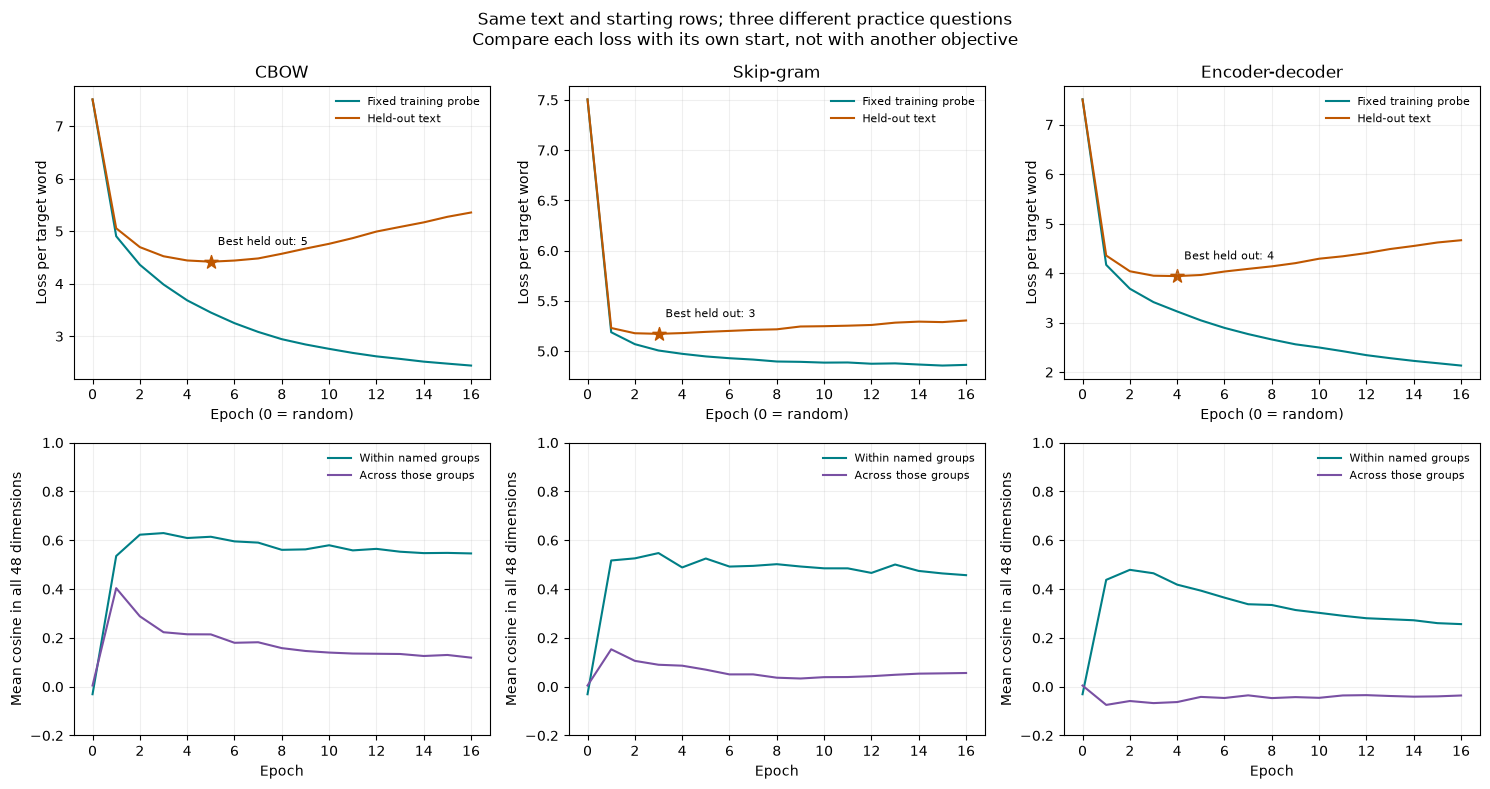

In [50]:
# ── Falling practice loss can hide worse guesses on new text ──
chart_directory = Path(real_text_embeddings.__file__).resolve().parent / "images"
loss_figure = plot_losses_and_geometry(real_results)
loss_figure.savefig(chart_directory / "03a-real-text-loss-and-similarity.png", dpi=130)
plt.show()
plt.close(loss_figure)


![Measured training and held-out loss for all three objectives, with within-group and across-group cosine similarity below.](images/03a-real-text-loss-and-similarity.png)
*Saved from the measured run; running the cell above regenerates this chart.*

Here's the complaint the tiny corpus hid: **we can get better at the practice questions and
worse at new passages at the same time.** The best held-out epochs were 5 for CBOW, 3 for
Skip-gram, and 4 for the writer. We deliberately show all 16 epochs instead of cropping off
the awkward part. These held-out stories are monitoring data, not an untouched final test set.

Now look at the writer's bottom panel. Its gap shoots up fastest (about **+0.54** by
epoch 2, higher than either other model ever gets), then slides down for the rest of training.
Hang on to that; we'll come back to it.

### Comparison: put the rows on one map with a fixed camera

A word has 48 coordinates. A page has two. We normalize the rows and fit **one PCA view**
to the recorded probe rows across all epochs and all three models. That view and the axis
limits stay fixed. We don't fit a fresh projection for every frame or line up separately
trained maps by eye.

Top row: the identical start. Bottom row: the final rows after the same fixed epoch budget.
Look for colours and feelings gathering into their own corners, but don't demand that every
group makes a tidy island. The shared projection keeps only about **24%** of this trajectory's
variance.
Two words can look close here while still differing in the other directions.

Shared 2D PCA keeps 24.4% of this probe trajectory's variance.
The cosine diagnostics use all 48 dimensions; the map is only a sketch.


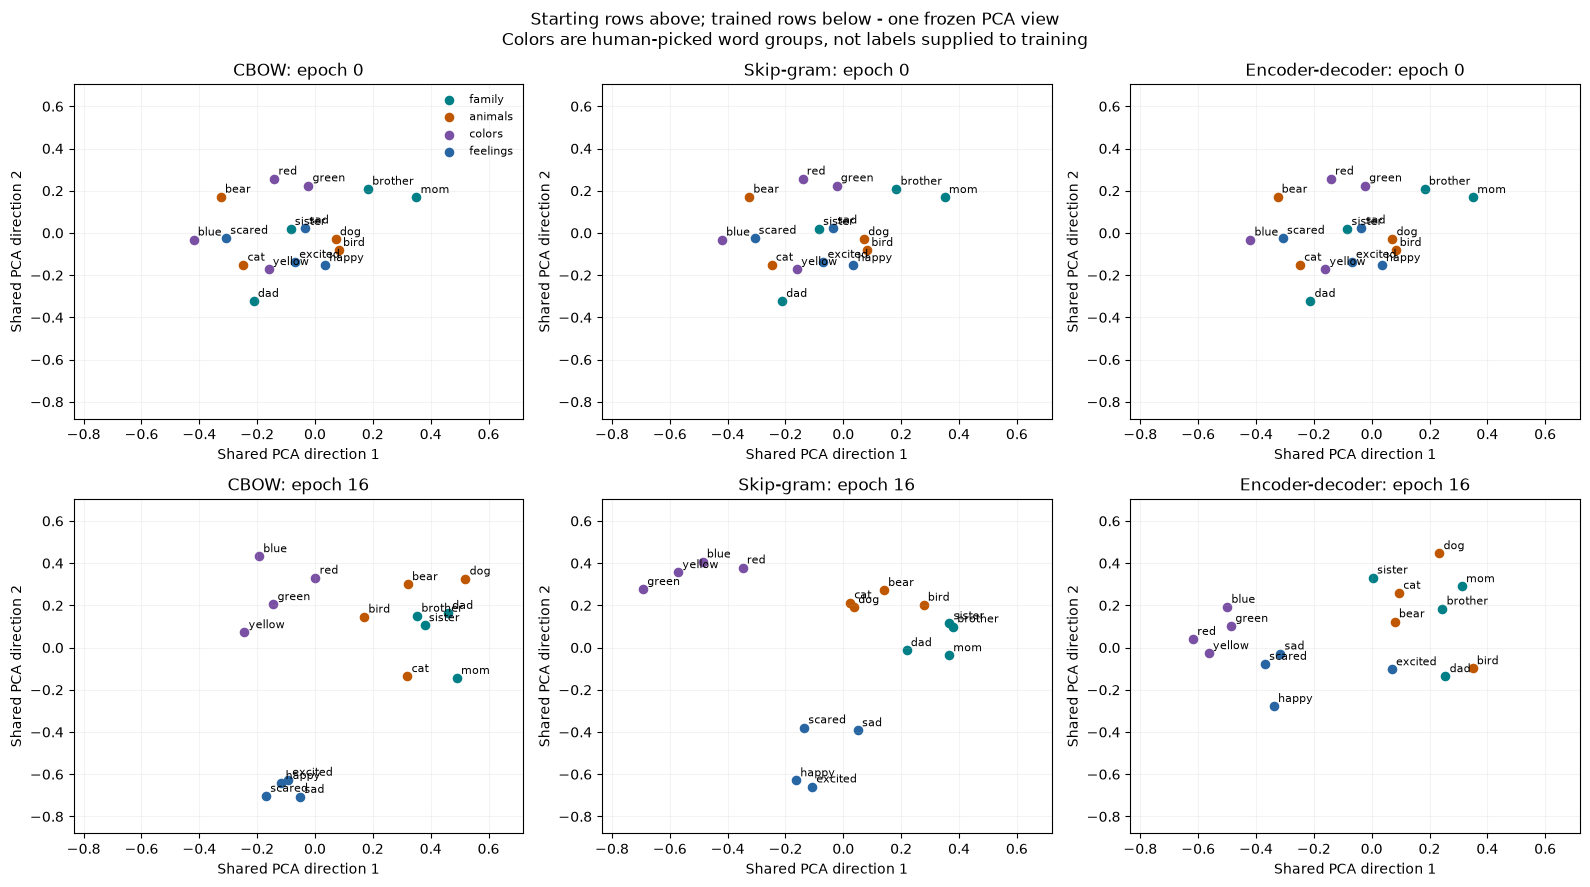

In [51]:
# ── One fixed camera for all three moving word maps ──
real_probe_words, real_coordinates, real_pca_fraction = project_snapshots(
    real_corpus, real_results,
)
map_figure = plot_word_maps(real_probe_words, real_coordinates, real_results)
map_figure.savefig(chart_directory / "03a-real-text-word-maps.png", dpi=130)
plt.show()
plt.close(map_figure)


![The same sixteen words at initialization and after training for CBOW, Skip-gram, and the encoder-decoder, using one frozen PCA projection.](images/03a-real-text-word-maps.png)
*The colors name our inspection groups. Training never receives those colors.*

### Comparison: check the full rows, not just the map

Each square below compares two complete 48-number word rows. Warmer means more similar
directions; cooler means less similar. The word order and color scale are identical in all
four panels. White diagonal squares are each word compared with itself, left out because
they'd always score one.

The thin lines divide our four groups. Look for warm blocks **inside** those boundaries
without the whole grid turning warm. CBOW and Skip-gram light up all four blocks; colours and
feelings are the hottest. CBOW also warms up a lot of the space *between* family and animals,
so it's tidier inside groups than it is at keeping them apart. The writer's colour and feelings
blocks are visible but paler, and its family and animal blocks are faint. It changes the stored
word rows too, but doesn't turn every relationship into the same pattern as the word-guessing
objectives. That's a finding, not a failure to
draw the graph attractively enough.

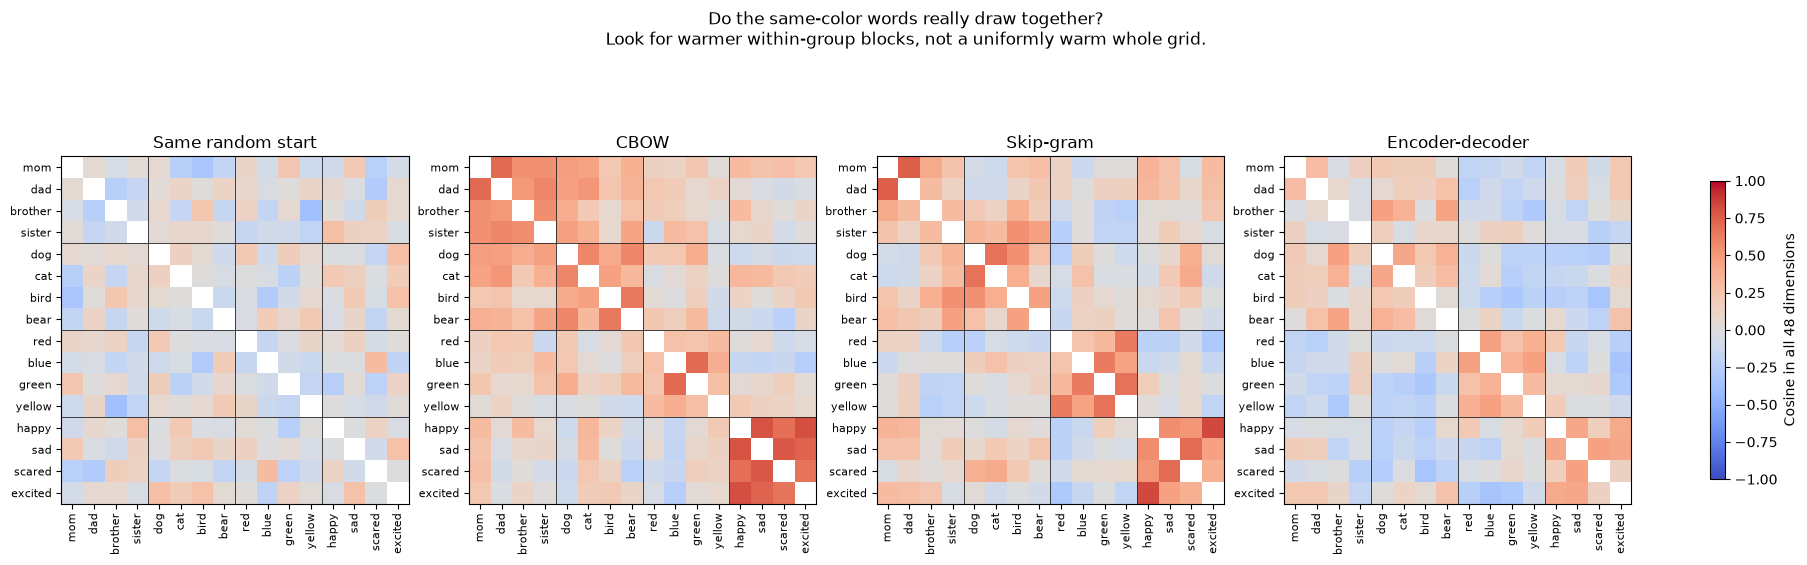

In [52]:
# ── Check the full rows, not just their two-dimensional shadows ──
similarity_figure = plot_similarity_heatmaps(real_corpus, real_results)
similarity_figure.savefig(chart_directory / "03a-real-text-cosine-heatmaps.png", dpi=130)
plt.show()
plt.close(similarity_figure)


![Cosine similarity heatmaps for the common random start and each trained model, computed in all 48 embedding dimensions with a shared scale.](images/03a-real-text-cosine-heatmaps.png)
*This checks the rows directly. It doesn't depend on the PCA camera.*

### Comparison: play the training history

Watch the same words move under the three practice questions. Each frame is a saved epoch,
not an invented path between two endpoints. The static maps and similarity chart above
carry the explanation if your viewer can't play the animation.

In [53]:
# ── Play the recorded epochs; no invented in-between training states ──
real_animation = animate_word_maps(real_probe_words, real_coordinates, real_results)
real_animation_html = real_animation.to_jshtml()
if "get_ipython" in globals():
    from IPython.display import HTML, display

    display(HTML(real_animation_html))
else:
    print(f"Recorded animation rendered ({len(real_animation_html):,} HTML characters).")


### Comparison: useful neighbours, or a friendly picture?

For each of the sixteen probe words, take its three closest **other probe words** in all
48 dimensions. What fraction belong to its named group? Randomly choosing three out of the
other fifteen would average **20%**. Our shared initialization scored **10.4%** (worse than chance, by luck of the draw).
After training: **85.4% CBOW, 72.9% Skip-gram, 68.8% encoder-decoder**.

That's a local sanity check on these probes, not overall vocabulary quality. So the code also
prints actual nearest words from the **whole vocabulary**, before and after training.
Some are useful; some are odd. Keep both. A model can improve on these sixteen words and
still have plenty of lousy neighbours elsewhere.

For a concrete pair, `mom` / `dad` cosine changed from **0.052** to **0.709** in CBOW,
**0.757** in Skip-gram, and **0.295** in the encoder-decoder. The corresponding final
across-group averages were **0.119**, **0.056**, and **-0.036**.
So this pair didn't just follow every other word into one pile.

These figures are from the recorded CPU run, not thresholds the code forces training to hit.
Different library versions may change the exact values. None of this makes similar words
interchangeable, proves that an embedding dimension has a particular meaning, or shows that
the encoder-decoder is the best way to learn word vectors.

In [54]:
# ── Useful neighbours, or merely nearby dots? ──
report_neighbours(real_corpus, real_results)


Full-vocabulary neighbours (not restricted to the colored words):

CBOW: group-neighbour purity 10.4% -> 85.4% (random among these probes: 20%)
  Best held-out epoch: 5; loss 4.419; final 5.356. Final maps show the fixed training budget, not a selected checkpoint.
  dad      before: mark, mum, naughty, screamed, soon; after: mommy, mom, billy, teacher, family
  cat      before: tired, naughty, gentle, dry, ship; after: bunny, sail, leaf, present, family
  blue     before: rest, pen, george, admired, spot; after: green, wrapped, beautiful, hope, winter
  sad      before: bike, feeling, vase, strong, pictures; after: happy, scared, nice, dizzy, ashamed

Skip-gram: group-neighbour purity 10.4% -> 72.9% (random among these probes: 20%)
  Best held-out epoch: 3; loss 5.173; final 5.305. Final maps show the fixed training budget, not a selected checkpoint.
  dad      before: mark, mum, naughty, screamed, soon; after: mom, mommy, mother, him, teacher
  cat      before: tired, naughty, gentle,

**Your turn:** predict whether `("mom", "sister")` or `("mom", "green")` will be more
similar after training. Change only `probe_pair` below and rerun this cell, not the training.
Compare with the across-group baseline as well as with the starting score.
Then try a pair that doesn't behave as you expected. That awkward example belongs in the lesson too.

In [55]:
# ── Your turn - change only the pair, without training again ──
probe_pair = ("mom", "dad")  # CHANGE THIS: try ("mom", "green"), without retraining
for objective, record in real_results.items():
    pair_ids = [real_corpus["word_ids"][word] for word in probe_pair]
    pair_scores = []
    for rows in (record["snapshots"][0], record["snapshots"][-1]):
        pair_vectors = torch.nn.functional.normalize(rows[pair_ids], dim=1)
        pair_scores.append((pair_vectors[0] @ pair_vectors[1]).item())
    print(f"{objective}: {' / '.join(probe_pair)} cosine "
          f"{pair_scores[0]:+.3f} -> {pair_scores[1]:+.3f}; "
          f"final across-group mean {record['across'][-1]:+.3f}")


CBOW: mom / dad cosine +0.052 -> +0.709; final across-group mean +0.119
Skip-gram: mom / dad cosine +0.052 -> +0.757; final across-group mean +0.056
Encoder-decoder: mom / dad cosine +0.052 -> +0.295; final across-group mean -0.036


### CBOW: inspect a shortlist at its best held-out epoch

At the very start we said a good guesser keeps a shortlist, not one answer, and that words used
alike should end up on it together. One familiar cat sentence cannot establish that; use the held-out blanks.

We'll ask the CBOW model saved at the epoch with its **lowest measured held-out loss**.
Give it two words on each side of a blank and look at its top five answers, with each one's share
of the chance. We hide `<unk>` from the list. The phrases below are ours; the stories never had
to contain them word for word.

**Predict:** for "was so ___ to have", will the model bet nearly everything on one word, or
spread its chances? And will the words it lists look related?


In [56]:
# ── Is a guess one word, or a shortlist? Ask CBOW at its best held-out epoch ──
cbow_best = real_results["CBOW"]["best_model"]
for left, right in [("was so", "to have"), ("a little", "named tom"),
                    ("played with", "toys and"), ("they went", "the park")]:
    menu = blank_shortlist(cbow_best, real_corpus, left, right)
    print(f"{left} ___ {right} -> " + ", ".join(f"{word} {chance:.0%}" for word, chance in menu))

shortlist = shortlist_summary(cbow_best, real_corpus)
print(f"\nAll {shortlist['blanks']:,} held-out blanks with a known answer:")
print(f"  right answer is the number-one guess:   {shortlist['first_right']:.1%}")
print(f"  right answer is somewhere in the top 5: {shortlist['shortlist_right']:.1%}")
print(f"  average share given to the first guess: {shortlist['first_share']:.1%}")
print(f"  how alike the 5 shortlisted words' rows are: {shortlist['shortlist_similarity']:+.3f}")
print(f"  how alike 5 random words' rows are:          {shortlist['random_similarity']:+.3f}")

assert shortlist["shortlist_right"] > shortlist["first_right"]
assert shortlist["shortlist_similarity"] > shortlist["random_similarity"]


was so ___ to have -> happy 44%, excited 14%, sad 6%, it 3%, he 2%
a little ___ named tom -> girl 67%, boy 16%, bird 4%, mouse 2%, dog 2%
played with ___ toys and -> his 28%, her 26%, their 7%, the 7%, with 3%
they went ___ the park -> to 86%, in 3%, and 2%, on 1%, outside 1%

All 3,816 held-out blanks with a known answer:
  right answer is the number-one guess:   24.9%
  right answer is somewhere in the top 5: 44.7%
  average share given to the first guess: 27.2%
  how alike the 5 shortlisted words' rows are: +0.238
  how alike 5 random words' rows are:          +0.120


On the authoring run, "was so ___ to have" gave **happy 44%, excited 14%, sad 6%**.
"a little ___ named tom" gave **girl 67%, boy 16%**, then bird, mouse and dog. "played with ___
toys and" split almost evenly between **his** and **her**. And "they went ___ the park" was nearly
a sure thing: **to 86%**. Sometimes the shortlist is really a one-item menu.

Across all **3,816** held-out blanks, the top guess was right **24.9%** of the time, but the right
answer was somewhere in the top five **44.7%** of the time. On average the first guess got only
about **27%** of the chance. The model is spreading its bets, not pretending to be sure.

Now the part that ties it back to the sensor profiles. The five words on each shortlist have rows that are
about **twice as alike** (+0.24) as five random words' rows (+0.12). That's the two jobs working
together: words that fit the same kind of slot got similar rows, so when one fits a blank, its
look-alikes get a share of the chance too.

Notice `sad` on the list next to `happy`. Alike rows mean "used in the same kinds of spots", not
"means the same thing". Our friend guessing "the cat sat on the ___" would make the same slip.

**Your turn:** change one phrase above to your own, keeping two known words on each side of the
blank. Can you find a blank where the shortlist is mostly grammar words (`a`, `the`, `to`)? What
does that tell you about what the slot is asking for?

A writer would have to *choose* one word from this menu, write it down, and guess again. How to
choose is a story for later. First, the blank has to move to the end.


### Encoder-decoder: is the writer just worse at word meaning?

Look at the final maps and heatmaps and you'd think so. But remember the bottom panel of the
loss chart: the writer's gap rose *fastest* and then leaked away. So which is it?

Think of three students learning vocabulary. CBOW and Skip-gram are doing flashcards: every
question is "which word goes with this word?", and the answer pushes **directly** on the word
profiles. Shared uses can encourage useful features in common, but no single
update is guaranteed to move whole profiles closer.

The writer is doing something else: reading three words and then writing the next two **in
order**. Its feedback reaches the word rows only *after* passing through the reader and writer
GRUs, which are happy to soak up some of the work themselves. It also has nearly twice the
parameters, so once the easy patterns are learned it's the first to start memorizing training
phrases. Memorizing exact phrases doesn't need `red` and `blue` to stay similar, so that
similarity slowly wears off.

That gives us a prediction we can check without training anything new: **read the same run at
each model's best held-out epoch instead of the last one.** If the writer is just bad at word
meaning, it will look bad there too. If it's overfitting, it should look a lot better early.

In [57]:
# ── Why does the writer's final map look weaker? Read the same run at its best epoch ──
writer_check = best_versus_final(real_results)
writer_record = writer_check["Encoder-decoder"]
if writer_record["final_gap"] < writer_record["best_gap"]:
    print("The writer's group separation faded after its best held-out checkpoint.")
else:
    print("This run did not show fading group separation; judge the recorded losses too.")


CBOW            best held-out epoch  5: gap +0.400, purity 81%  |  last epoch: gap +0.427, purity 85%
Skip-gram       best held-out epoch  3: gap +0.458, purity 83%  |  last epoch: gap +0.401, purity 73%
Encoder-decoder best held-out epoch  4: gap +0.481, purity 67%  |  last epoch: gap +0.293, purity 69%
The writer's group separation faded after its best held-out checkpoint.


Read the printed best-versus-final table before choosing an explanation.
The writer's group gap can rise early and fade later even while its training loss keeps
falling. That is evidence about **this recorded run**, not a rule that every seed must obey.
The conditional message reports whether fading actually happened.

A larger recurrent predictor has additional routes for fitting the data. That is a possible
explanation, not an isolated causal experiment: target counts, parameters, and computation
also differ. Keep the best held-out checkpoint for these diagnostics, rather than assuming
the final epoch is best. Optional seed checks below cost another full comparison each;
they are **off by default** and are not evidence unless you run them.


In [58]:
# ── Optional: is that one lucky seed? (about two minutes per extra seed) ──
RUN_SEED_CHECK = False
if RUN_SEED_CHECK:
    for check_seed in (5, 123):
        print(f"--- seed {check_seed}")
        best_versus_final(train_comparison(
            real_corpus, CBOW, SkipGram, EncoderDecoderLM,
            epochs=REAL_TEXT_EPOCHS, seed=check_seed, verbose=False,
        ))
else:
    print("Skipped. Set RUN_SEED_CHECK = True to retrain with seeds 5 and 123.")
print(f"Whole default lesson: {time.perf_counter() - notebook_started:.1f}s "
      "(cache verified, one CPU thread; first download is extra).")


Skipped. Set RUN_SEED_CHECK = True to retrain with seeds 5 and 123.
Whole default lesson: 221.4s (cache verified, one CPU thread; first download is extra).


## 14 - The short version

- The text supplies the practice. Slide within each sentence, hide a word,
  and use the original word as the answer. No hand-written labels needed.
- IDs stay put. Training changes the stored embedding rows and predictor
  weights, not the words' addresses.
- Same text, different jobs: CBOW guesses the middle word, Skip-gram guesses
  a neighbour, and the writer predicts a continuation. Different pairs;
  the same training loop.
- Averaging throws away order. More epochs won't bring back information
  we removed before prediction.
- Practising with correct previous words isn't writing unaided. Check what
  the writer produces when it has to use its own guesses.
- Lower training loss isn't the finish line. Check new stories, the whole
  shortlist, and the actual rows. A tidy 2D plot doesn't prove useful meaning.

**Where we stopped**

- **Built and ran:** the three objectives, shared training, greedy generation,
  and held-out embedding checks.
- **Talked through:** one-hot equivalence, static versus contextual rows,
  and the limits of one final summary.
- **Left for later:** negative sampling, weight tying, beam search,
  variable-length batches, and [attention in 03D](03D-recurrent-encoder-decoder-to-attention.ipynb).


### Next: give the words seats

You can now make practice questions from text and use them to train word rows and a predictor
together. You also saw a preview of a reader handing a note to a writer.

CBOW's blank had clues on **both** sides. The writer preview already used
left-to-right continuation, but it hid the reading and writing inside recurrent
layers. When you write, the blank is at the end; once you pick a word, the next
blank appears after it. 03B slows down that game with counts and fixed windows
before we return to recurrent readers and writers.

But first, let's not skip the problem we left behind: **averaging erased word order.**
Would keeping the words in separate seats fix everything? Continue to
[03B - Counts and Fixed Windows](03B-counts-and-fixed-window-language-models.ipynb).
The Stage 04 links above are a look ahead; 03B-03D build the bridge to get there.


### The two example threads now meet

The **lookup microscope** grew from fetching `the` and `sat` to averaging
their rows, exposing the loss of order. The **learning game** grew from
supplied `cat/dog` cards to text-made questions, exposing what different
objectives can teach. Lookup itself never changed its job.

Carry this exact complaint into the next notebook: **averaging erased word
order. Would keeping the words in separate seats fix everything?**
Better learned rows alone cannot recover the discarded order.
